# BÀI KIỂM TRA 3: TỐI ƯU HÓA, CẢI TIẾN VÀ SO SÁNH MÔ HÌNH
**Học phần:** Học máy
**Đề tài:** Dự báo điện năng tiêu thụ của hộ gia đình dựa trên dữ liệu đo theo thời gian
**Notebook tiếp nối:** dùng `hourly.parquet` do `01_eda.ipynb` tạo ra và kết quả kiểm định chéo `ket_qua/cv_*.csv` do `03_huan_luyen_danh_gia.ipynb` ghi ra.

---

## 1. Mục tiêu của notebook

1. Chỉ ra hạn chế của các mô hình ở Bài kiểm tra 2 bằng bằng chứng: đường cong học tập, đường cong kiểm định theo độ phức tạp, lỗi tập trung ở giờ đỉnh.
2. Cải tiến đặc trưng (công tơ phụ, ngày lễ), thử mô hình mới (Ridge, tổ hợp Voting) và tối ưu siêu tham số bằng tìm kiếm ngẫu nhiên trên **cùng 5 fold kiểm định chéo**.
3. Lập bảng ablation thể hiện đóng góp của từng thay đổi trong cùng điều kiện (cùng dữ liệu, cùng fold, cùng tập mẫu, cùng chỉ số).
4. Chốt mô hình cuối **trước** khi dùng tập kiểm tra, rồi đánh giá **một lần** trên tập kiểm tra năm 2010.

Quy tắc xuyên suốt: mọi lựa chọn (đặc trưng, siêu tham số, mô hình) chỉ dựa trên kiểm định chéo trong tập huấn luyện (nhãn trước 01/01/2010). Tập kiểm tra chỉ được dùng ở mục 9, sau khi cấu hình cuối đã được ghi ra file; các kết quả trên tập kiểm tra chỉ dùng để báo cáo, không dùng để chọn hay chỉnh bất cứ điều gì.

## 2. Thiết lập môi trường và tham số

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

sys.path.insert(0, str(Path("..").resolve()))      # để import thư mục src/ của dự án
from src.evaluation import (common_sample_folds, evaluate_test, learning_curve_ts, run_cv,
                            time_series_folds)
from src.features import feature_columns, load_hourly_frame, make_features, train_test_tables
from src.models import (BASELINES, RANDOM_STATE, make_linear, make_random_forest, make_ridge, make_voting,
                        make_xgboost)

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 11,
                     "axes.labelsize": 10, "figure.dpi": 120})
RESULTS_DIR = Path("../ket_qua")
RESULTS_DIR.mkdir(exist_ok=True)
np.random.seed(RANDOM_STATE)
# Khi tập huấn luyện quá ngắn (đường cong học tập với 1.000 giờ) không chứa đủ 12 tháng, OneHotEncoder của
# Linear Regression gặp tháng "lạ" ở phần kiểm định và mã hóa thành toàn 0 (handle_unknown="ignore").
# Đây là hành vi mong muốn; tắt cảnh báo này để kết quả dễ đọc.
warnings.filterwarnings("ignore", message="Found unknown categories")

In [2]:
# Ô THAM SỐ
HORIZONS = [1, 6, 12, 24]                       # tầm dự báo (giờ), giống Bài kiểm tra 2
TEST_START = "2010-01-01"                       # mốc chia huấn luyện / kiểm tra (theo thời điểm mục tiêu)
N_SPLITS, TEST_SIZE, GAP = 5, 24 * 90, 168      # cùng 5 fold TimeSeriesSplit như Bài kiểm tra 2
N_ITER_RF, N_ITER_XGB = 20, 30                  # số cấu hình thử trong tìm kiếm ngẫu nhiên
SEEDS = [0, 1, 2, 3, 4]                         # các hạt giống để kiểm tra độ ổn định ở mục 10
colors = {"Naive": "gray", "SNaive24": "silver", "SNaive168": "darkgray", "LinearRegression": "tab:blue",
          "Ridge": "tab:cyan", "RandomForest": "tab:green", "XGBoost": "tab:orange", "Voting": "tab:red"}

## 3. Dữ liệu và bảng đặc trưng

Bảng đặc trưng được tạo **một lần** với đầy đủ các đặc trưng mới; mỗi thí nghiệm chỉ chọn một tập con cột. Nhờ vậy mọi thí nghiệm dùng đúng cùng các dòng, cùng fold và cùng tập mẫu kiểm định.

| Bộ đặc trưng | Gồm | Số cột |
|---|---|---|
| `BASE` | 21 đặc trưng của Bài kiểm tra 2 (trễ, cùng giờ ngày/tuần trước, cửa sổ trượt, lịch) | 21 |
| `SUB` | `BASE` + điện năng của 3 nhóm công tơ phụ tại $t$ và $t-1$ | 27 |
| `HOL` | `BASE` + cờ ngày lễ Pháp và cờ ngày liền kề ngày lễ của thời điểm mục tiêu | 23 |
| `ALL` | `BASE` + `SUB` + `HOL` | 29 |

In [3]:
hourly = load_hourly_frame()
tables, folds, cv_folds = {}, {}, {}
for h in HORIZONS:
    df = make_features(hourly, h, submeter=True, holiday=True)
    train, test = train_test_tables(df, TEST_START)
    tables[h] = (train, test)
    folds[h] = time_series_folds(train, N_SPLITS, TEST_SIZE, GAP)
    cv_folds[h] = common_sample_folds(train, folds[h])    # dùng cho GridSearchCV / RandomizedSearchCV

ALL = feature_columns(df)
SUB_COLS = [c for c in ALL if c.startswith("sub")]
HOL_COLS = ["is_holiday", "near_holiday"]
BASE = [c for c in ALL if c not in SUB_COLS + HOL_COLS]
FEATURE_SETS = {"BASE": BASE, "SUB": BASE + SUB_COLS, "HOL": BASE + HOL_COLS, "ALL": ALL}
print({k: len(v) for k, v in FEATURE_SETS.items()})
print("Đặc trưng mới:", SUB_COLS + HOL_COLS)
train1 = tables[1][0]
print(f"Số giờ huấn luyện có nhãn ngày lễ: {train1.is_holiday.sum():,} | liền kề ngày lễ: {train1.near_holiday.sum():,}")

{'BASE': 21, 'SUB': 27, 'HOL': 23, 'ALL': 29}
Đặc trưng mới: ['sub1_lag_0', 'sub1_lag_1', 'sub2_lag_0', 'sub2_lag_1', 'sub3_lag_0', 'sub3_lag_1', 'is_holiday', 'near_holiday']
Số giờ huấn luyện có nhãn ngày lễ: 768 | liền kề ngày lễ: 1,541


In [4]:
# Kiểm tra không rò rỉ: thay toàn bộ dữ liệu sau mốc T, đặc trưng tại mọi t <= T phải giữ nguyên
T = pd.Timestamp("2009-06-01 12:00")
perturbed = hourly.copy()
perturbed.loc[perturbed.index > T, ["energy_kwh", "sub1_kwh", "sub2_kwh", "sub3_kwh"]] = 999.0
before = make_features(hourly, 24, submeter=True, holiday=True).loc[:T, ALL]
after = make_features(perturbed, 24, submeter=True, holiday=True).loc[:T, ALL]
pd.testing.assert_frame_equal(before, after)
print("Đúng: các đặc trưng mới tại mọi t <= T không phụ thuộc dữ liệu sau T.")

Đúng: các đặc trưng mới tại mọi t <= T không phụ thuộc dữ liệu sau T.


## 4. Hạn chế của mô hình ban đầu

### 4.1 Nhắc lại kết quả Bài kiểm tra 2

In [5]:
bkt2 = pd.read_csv(RESULTS_DIR / "cv_summary.csv")
bkt2_tv = pd.read_csv(RESULTS_DIR / "cv_train_vs_val.csv")
bkt2.pivot(index="model", columns="h", values="MAE_mean").loc[
    ["Naive", "SNaive168", "LinearRegression", "RandomForest", "XGBoost"]].round(3)

h,1,6,12,24
model,,,,
Naive,0.440,0.971,0.781,0.630
SNaive168,0.602,0.602,0.602,0.603
LinearRegression,0.384,0.508,0.509,0.507
RandomForest,0.365,0.482,0.488,0.495
XGBoost,0.366,0.488,0.488,0.507


Bài kiểm tra 2 để lại ba câu hỏi: (1) khoảng cách giữa MAE huấn luyện trong mẫu và MAE kiểm định của mô hình cây (gấp 1,4--1,6 lần) có phải quá khớp thật không; (2) Linear Regression có chưa khớp không; (3) sai số dồn vào giờ đỉnh có giảm được bằng thông tin mới không.

### 4.2 Đường cong học tập

Ở mỗi fold, mô hình được huấn luyện trên $n$ mẫu **gần nhất** trước phần kiểm định (giữ nguyên khoảng đệm 168 giờ), với $n$ từ 1.000 đến cỡ phần huấn luyện của fold 1 (fold nhỏ nhất, khoảng 15.500 giờ) để mọi điểm đều tính trên đủ 5 fold, rồi đo MAE trong mẫu và MAE kiểm định. Siêu tham số giữ như Bài kiểm tra 2.

In [6]:
SIZES = [1000, 2000, 4000, 8000, 12000]   # cộng thêm điểm cuối bằng cỡ phần huấn luyện của fold 1
LC_MODELS = {"LinearRegression": make_linear, "RandomForest": make_random_forest, "XGBoost": make_xgboost}
t0 = time.time()
lc = []
for h in (1, 24):
    train = tables[h][0]
    # Điểm cuối = cỡ phần huấn luyện nhỏ nhất (fold 1), để mọi điểm đều có đủ 5 fold
    sizes = SIZES + [min(len(tr) for tr, _ in folds[h])]
    for name, make in LC_MODELS.items():
        lc.append(learning_curve_ts(train, BASE, folds[h], make, sizes).assign(h=h, model=name))
lc = pd.concat(lc, ignore_index=True)
lc.to_csv(RESULTS_DIR / "toi_uu_learning_curve.csv", index=False)
print(f"Thời gian: {time.time() - t0:.0f} giây")
lc.groupby(["h", "model", "n_train"])[["MAE_train", "MAE_val"]].mean().unstack("n_train").round(3)

Thời gian: 99 giây


MAE_train                                            \
n_train                 1000   2000   4000   8000   12000  15532  15555   
h  model                                                                  
1  LinearRegression     0.340  0.344  0.360  0.382  0.391    NaN  0.400   
   RandomForest         0.223  0.216  0.220  0.227  0.232    NaN  0.237   
   XGBoost              0.034  0.067  0.119  0.182  0.219    NaN  0.244   
24 LinearRegression     0.424  0.441  0.467  0.502  0.510  0.527    NaN   
   RandomForest         0.262  0.265  0.273  0.288  0.292  0.302    NaN   
   XGBoost              0.035  0.078  0.138  0.219  0.272  0.306    NaN   

                    MAE_val                                            
n_train               1000   2000   4000   8000   12000  15532  15555  
h  model                                                               
1  LinearRegression   0.516  0.407  0.405  0.386  0.385    NaN  0.386  
   RandomForest       0.416  0.402  0.391  0.369  0.368    NaN  0.366  
   XGBoost            0.444  0.424  0.410  0.374  0.370    NaN  0.367  
24 LinearRegression   0.666  0.577  0.609  0.518  0.511  0.512    NaN  
   RandomForest       0.565  0.546  0.534  0.499  0.498  0.497    NaN  
   XGBoost            0.596  0.566  0.562  0.512  0.511  0.509    NaN

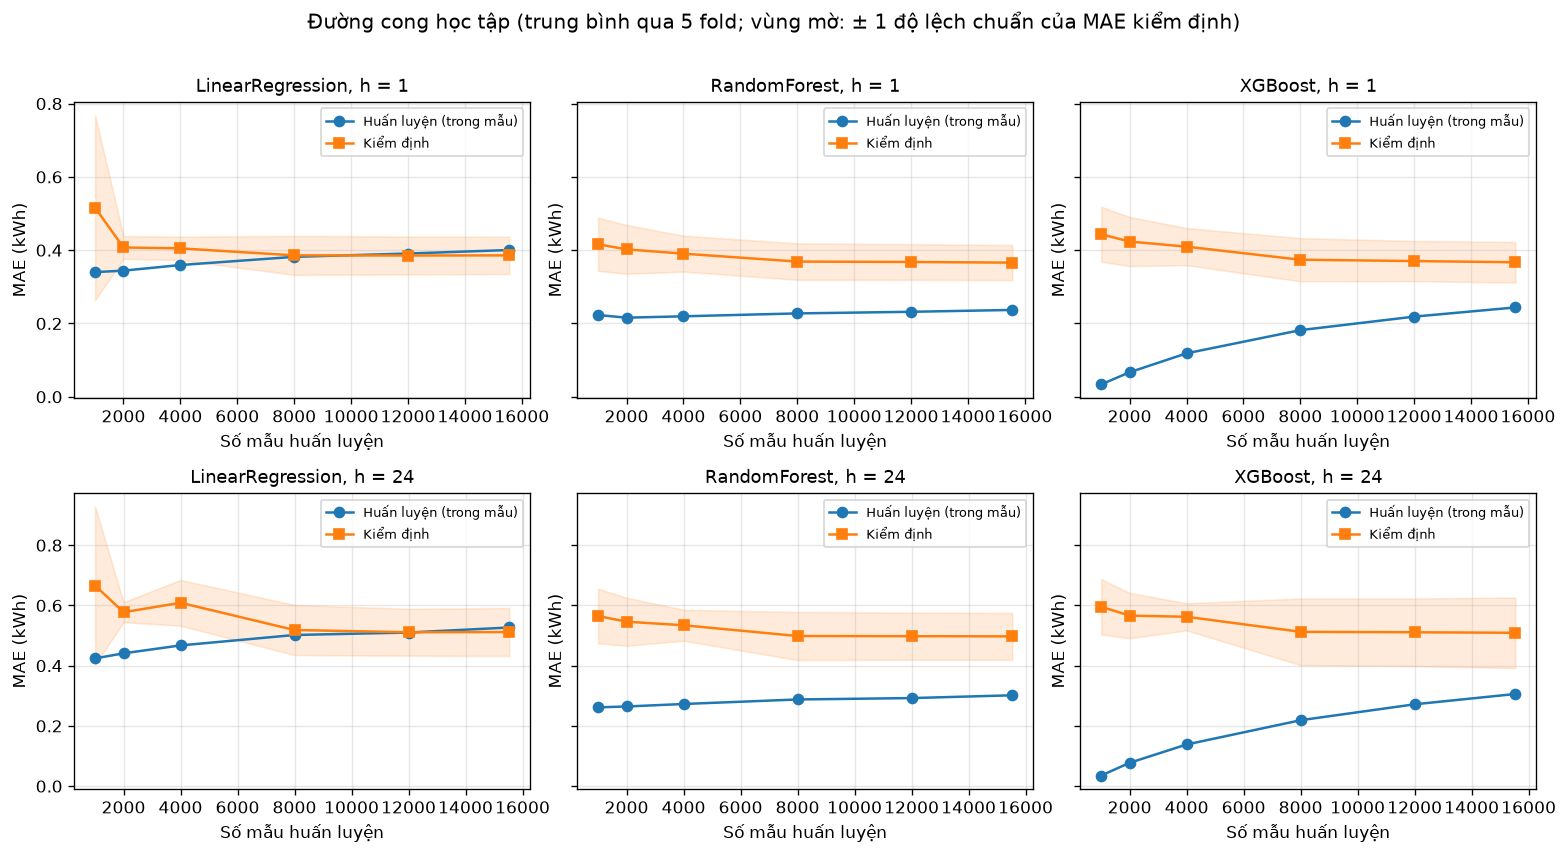

In [7]:
# HINH: duong_cong_hoc_tap
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey="row")
for r, h in enumerate((1, 24)):
    for c, name in enumerate(LC_MODELS):
        g = lc[(lc.h == h) & (lc.model == name)].groupby("n_train")[["MAE_train", "MAE_val"]]
        m, s = g.mean(), g.std()
        ax = axes[r, c]
        ax.plot(m.index, m.MAE_train, "o-", label="Huấn luyện (trong mẫu)")
        ax.plot(m.index, m.MAE_val, "s-", label="Kiểm định")
        ax.fill_between(m.index, m.MAE_val - s.MAE_val, m.MAE_val + s.MAE_val, alpha=0.15, color="tab:orange")
        ax.set(title=f"{name}, h = {h}", xlabel="Số mẫu huấn luyện", ylabel="MAE (kWh)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.suptitle("Đường cong học tập (trung bình qua 5 fold; vùng mờ: ± 1 độ lệch chuẩn của MAE kiểm định)", y=1.01)
plt.tight_layout()
plt.show()

> **Nhận xét đường cong học tập:**
> - **Linear Regression chưa khớp:** sai số huấn luyện tăng dần ($0,340 \rightarrow 0,400$ kWh ở $h = 1$) và gặp sai số kiểm định từ khoảng 8.000 mẫu ($0,382$ và $0,386$). Hai đường gần nhau ở mức sai số cao hơn mô hình cây: thêm dữ liệu không giúp được nhiều, mô hình thiếu khả năng biểu diễn.
> - **Random Forest:** sai số trong mẫu gần như không đổi ($0,22$--$0,24$ kWh ở $h = 1$) vì mỗi cây luôn khớp sát dữ liệu của nó; sai số kiểm định giảm khi tăng dữ liệu ($0,416 \rightarrow 0,366$ ở $h = 1$; $0,565 \rightarrow 0,497$ ở $h = 24$).
> - **XGBoost:** với 1.000 mẫu, sai số trong mẫu chỉ $0,034$ kWh trong khi kiểm định $0,444$ (ở $h = 1$): với ít dữ liệu, 400 cây độ sâu 6 gần như học thuộc dữ liệu. Khi tăng dữ liệu, khoảng cách thu hẹp dần ($0,244$ và $0,367$ ở 15.555 mẫu).
> - Với hai mô hình cây, sai số kiểm định giảm nhanh đến khoảng 8.000 mẫu rồi gần như đi ngang (Linear Regression ở $h = 24$ dao động khi dữ liệu ít, rồi cũng đi ngang từ 8.000 mẫu) (ở $h = 24$: Random Forest $0,499 \rightarrow 0,497$, XGBoost $0,512 \rightarrow 0,509$ từ 8.000 đến khoảng 15.500 mẫu). Thêm dữ liệu cùng loại khó cải thiện đáng kể; cần thông tin mới (đặc trưng) thay vì nhiều mẫu hơn.

### 4.3 Đường cong kiểm định theo độ phức tạp của cây

Nếu mô hình cây quá khớp thật, giảm độ phức tạp (tăng số mẫu tối thiểu ở lá của Random Forest, giảm độ sâu của XGBoost) sẽ làm MAE **kiểm định** giảm. Mỗi giá trị được chạy kiểm định chéo đủ 5 fold, các tham số khác giữ như Bài kiểm tra 2.

In [8]:
VC = {"RandomForest": ("min_samples_leaf", [1, 2, 5, 10, 20, 50, 100, 200], make_random_forest),
      "XGBoost": ("max_depth", [2, 3, 4, 6, 8, 10], make_xgboost)}
t0 = time.time()
vc = []
for h in (1, 24):
    train = tables[h][0]
    for name, (param, values, make) in VC.items():
        for v in values:
            sc, _, _ = run_cv(train, BASE, folds[h],
                              models={name: lambda cols, make=make, param=param, v=v: make(cols, **{param: v})})
            sc = sc[sc.model == name]
            for s in ("train", "val"):
                d = sc[sc.set == s].MAE
                vc.append({"h": h, "model": name, "param": param, "value": v, "set": s,
                           "MAE_mean": d.mean(), "MAE_std": d.std()})
vc = pd.DataFrame(vc)
vc.to_csv(RESULTS_DIR / "toi_uu_validation_curve.csv", index=False)
print(f"Thời gian: {time.time() - t0:.0f} giây")
vc.pivot_table(index=["model", "value"], columns=["h", "set"], values="MAE_mean").round(3)

Thời gian: 252 giây


h                      1             24       
set                 train    val  train    val
model        value                            
RandomForest 1      0.142  0.369  0.180  0.501
             2      0.166  0.366  0.212  0.498
             5      0.241  0.365  0.311  0.495
             10     0.297  0.365  0.388  0.494
             20     0.336  0.367  0.446  0.495
             50     0.370  0.372  0.496  0.499
             100    0.388  0.380  0.519  0.504
             200    0.405  0.390  0.538  0.512
XGBoost      2      0.386  0.376  0.519  0.511
             3      0.364  0.367  0.485  0.507
             4      0.338  0.364  0.448  0.505
             6      0.265  0.366  0.339  0.507
             8      0.163  0.368  0.204  0.504
             10     0.077  0.372  0.097  0.509

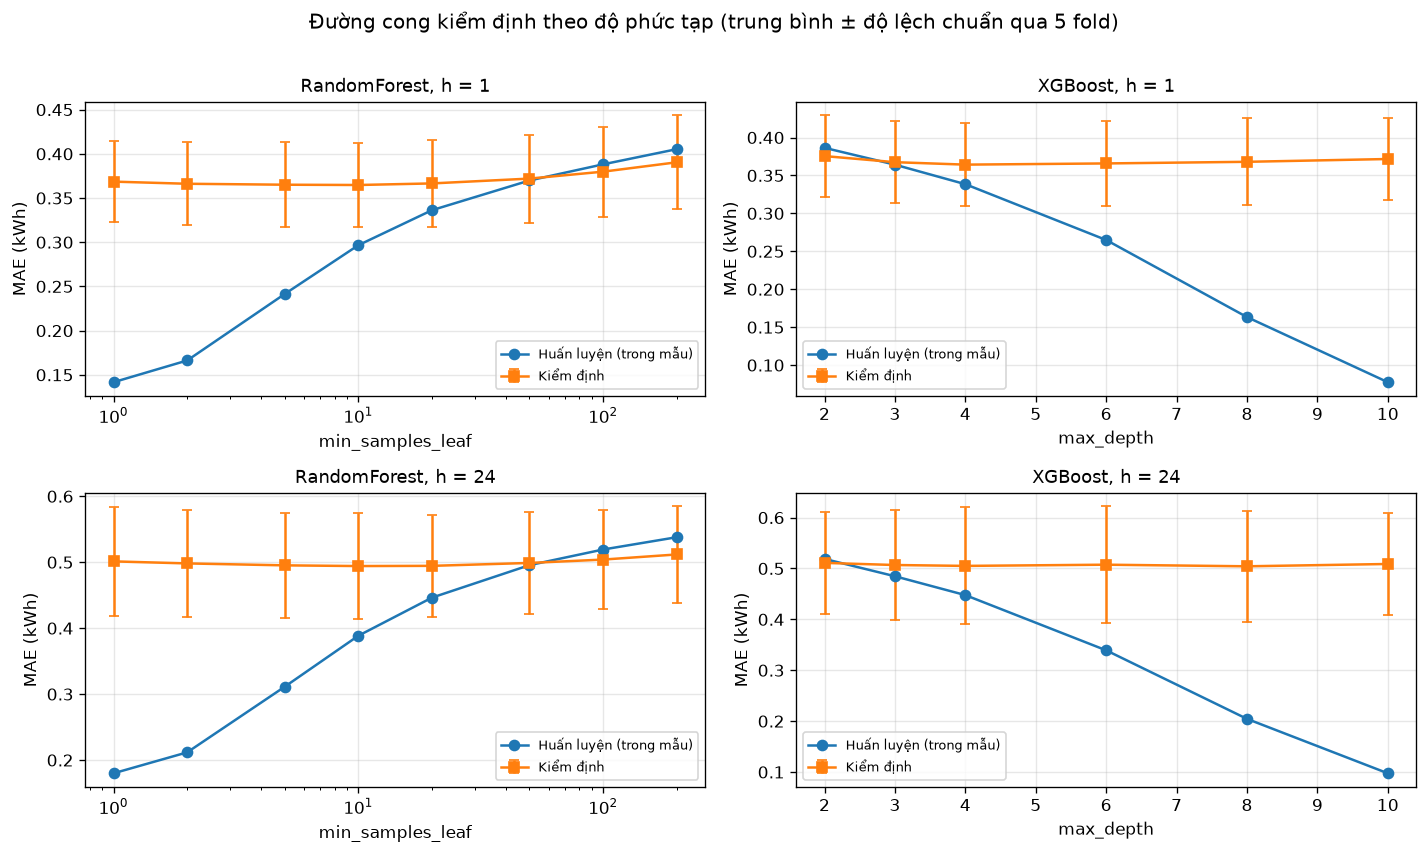

In [9]:
# HINH: duong_cong_kiem_dinh
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r, h in enumerate((1, 24)):
    for c, (name, (param, values, _)) in enumerate(VC.items()):
        ax = axes[r, c]
        for s, mk, lab in (("train", "o-", "Huấn luyện (trong mẫu)"), ("val", "s-", "Kiểm định")):
            d = vc[(vc.h == h) & (vc.model == name) & (vc.set == s)]
            ax.errorbar(d.value, d.MAE_mean, yerr=d.MAE_std if s == "val" else None, fmt=mk, capsize=3, label=lab)
        ax.set(title=f"{name}, h = {h}", xlabel=param, ylabel="MAE (kWh)")
        if name == "RandomForest":
            ax.set_xscale("log")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.suptitle("Đường cong kiểm định theo độ phức tạp (trung bình ± độ lệch chuẩn qua 5 fold)", y=1.01)
plt.tight_layout()
plt.show()

> **Nhận xét đường cong kiểm định:**
> - Khi tăng độ phức tạp (giảm số mẫu tối thiểu ở lá của Random Forest, tăng độ sâu của XGBoost), sai số **trong mẫu** giảm rất mạnh: Random Forest từ $0,405$ xuống $0,142$ kWh, XGBoost từ $0,386$ xuống $0,077$ kWh ở $h = 1$.
> - Nhưng sai số **kiểm định** gần như không đổi: Random Forest $0,365$--$0,372$ kWh với số mẫu ở lá từ 1 đến 50 (thấp nhất ở 5--10), chỉ tăng rõ khi cây quá đơn giản (200 mẫu: $0,390$); XGBoost $0,364$--$0,376$ với độ sâu 2--10 (thấp nhất ở độ sâu 4). Ở $h = 24$ đường kiểm định còn phẳng hơn ($0,494$--$0,512$ và $0,504$--$0,511$).
> - **Kết luận:** khoảng cách giữa sai số trong mẫu và sai số kiểm định ở Bài kiểm tra 2 chủ yếu do cách đo trong mẫu của mô hình cây, **không phải quá khớp gây hại**: giảm độ phức tạp không làm sai số kiểm định giảm. Cấu hình của Bài kiểm tra 2 (5 mẫu ở lá, độ sâu 6) đã nằm gần đáy của đường kiểm định. Vì vậy cải tiến cần đến từ **thông tin mới** (đặc trưng) hơn là từ điều chuẩn mạnh hơn.

### 4.4 Lỗi tập trung ở giờ đỉnh

Bảng dưới lấy lại kết quả phân tích lỗi của Bài kiểm tra 2 (dự báo kiểm định của 5 fold).

In [10]:
pd.read_csv(RESULTS_DIR / "cv_error_concentration.csv").round(3)

,h,Mô hình,Sai lệch TB ở 5% giờ cao nhất (kWh),Sai lệch TB ở 10% giờ thấp nhất (kWh),Tỷ trọng sai số của 10% giờ sai nhiều nhất (%)
0,1,LinearRegression,-1.112,0.214,33.154
1,1,RandomForest,-1.148,0.201,34.468
2,1,XGBoost,-1.061,0.189,34.361
3,24,LinearRegression,-1.626,0.425,30.560
4,24,RandomForest,-1.603,0.438,31.283
5,24,XGBoost,-1.436,0.440,31.608


> **Nhận xét lỗi tập trung:** 5% giờ tiêu thụ cao nhất bị dự báo thấp trung bình $1,06$--$1,15$ kWh ($h = 1$) và $1,44$--$1,63$ kWh ($h = 24$); 10% số giờ sai nhiều nhất chiếm $30,6$--$34,5\%$ tổng sai số. Các đỉnh này do thiết bị được bật (bếp, máy giặt, bình nước nóng), là thông tin mà tổng điện năng $y_t$ không cho biết.

### 4.5 Bảng hạn chế -- giải pháp

| Hạn chế | Bằng chứng | Giải pháp | Cơ sở |
|---|---|---|---|
| Mô hình không biết thiết bị nào đang chạy, dự báo thấp các đỉnh | Mục 4.4: lỗi dồn vào 5% giờ cao nhất; tầm quan trọng của `lag_0` áp đảo ở $h = 1$ (Bài kiểm tra 2) | Thêm điện năng của 3 nhóm công tơ phụ tại $t$, $t-1$ | Thông tin quá khứ của chuỗi liên quan, có sẵn tại $t$ |
| Đặc trưng lịch không phân biệt ngày lễ với ngày thường | Ngày lễ có nhịp sinh hoạt khác nhưng `dayofweek` coi như ngày thường | Cờ ngày lễ Pháp và ngày liền kề | Biến biết trước về thời điểm mục tiêu |
| Siêu tham số chọn theo giá trị phổ biến, chưa kiểm chứng | Bài kiểm tra 2 | Tìm kiếm ngẫu nhiên trên cùng 5 fold | Tối ưu siêu tham số bằng kiểm định chéo |
| Linear Regression chưa khớp | Mục 4.2: hai đường gặp nhau ở mức sai số cao | Thử Ridge để xác nhận rằng điều chuẩn không giúp; giữ mô hình cây | Điều chuẩn giảm phương sai, không giảm độ chệch |
| Random Forest và XGBoost sai số gần nhau nhưng xây dựng khác nhau | Bài kiểm tra 2: chênh lệch không quá $0,013$ kWh | Tổ hợp Voting lấy trung bình hai mô hình | Kết hợp dự báo giảm rủi ro chọn sai một mô hình |
| Mô hình cây quá khớp? | Mục 4.3: **không** được xác nhận | Không cần điều chuẩn mạnh hơn | Đường cong kiểm định phẳng |
| Thêm dữ liệu cùng loại gần như không giúp | Mục 4.2: sai số kiểm định đi ngang từ khoảng 8.000 mẫu | Ưu tiên thông tin mới (đặc trưng) thay vì thêm mẫu | Đường cong học tập |

## 5. Cải tiến đặc trưng

Hai nhóm đặc trưng mới, mỗi nhóm gắn với một hạn chế ở mục 4:

1. **Điện năng của từng nhóm công tơ phụ tại $t$ và $t-1$** (bếp, giặt là, bình nước nóng và điều hòa). Tổng điện năng $y_t$ không cho biết thiết bị nào đang chạy; một thiết bị có chu kỳ dài (ví dụ máy giặt, bình nước nóng) đang chạy ở $t$ gợi ý mức tiêu thụ ở $t+1$. Chỉ dùng giá trị đến thời điểm gốc $t$ nên không rò rỉ.
2. **Cờ ngày lễ Pháp** của ngày mục tiêu và cờ ngày liền kề ngày lễ (thư viện `holidays`). Ngày lễ có nhịp sinh hoạt giống cuối tuần nhưng đặc trưng `dayofweek` không biết điều đó. Lịch ngày lễ biết trước nên được dùng cho thời điểm mục tiêu.

Thí nghiệm giữ nguyên siêu tham số của Bài kiểm tra 2, chỉ đổi bộ đặc trưng, để tách riêng tác động của dữ liệu.

In [11]:
FEAT_MODELS = {"LinearRegression": make_linear, "RandomForest": make_random_forest, "XGBoost": make_xgboost}
t0 = time.time()
feat_scores = []
for h in HORIZONS:
    train = tables[h][0]
    for fs, cols in FEATURE_SETS.items():
        sc, _, _ = run_cv(train, cols, folds[h], models=FEAT_MODELS)
        feat_scores.append(sc[sc.model.isin(FEAT_MODELS)].assign(h=h, features=fs))
feat_scores = pd.concat(feat_scores, ignore_index=True)
feat_scores.to_csv(RESULTS_DIR / "toi_uu_feature_scores.csv", index=False)
print(f"Thời gian: {time.time() - t0:.0f} giây")

fv = feat_scores[feat_scores.set == "val"]
feat_summary = fv.groupby(["h", "model", "features"]).MAE.agg(["mean", "std"]).reset_index()
base_fold = fv[fv.features == "BASE"].set_index(["h", "model", "fold"]).MAE.sort_index()
feat_summary["Số fold tốt hơn BASE"] = [
    int((fv[(fv.h == r.h) & (fv.model == r.model) & (fv.features == r.features)].set_index(["h", "model", "fold"]).MAE
         < base_fold.loc[(r.h, r.model)].values).sum()) for r in feat_summary.itertuples()]
feat_summary.pivot_table(index=["model", "features"], columns="h", values="mean").round(4)

Thời gian: 294 giây


h                              1       6       12      24
model            features                                
LinearRegression ALL       0.3785  0.5063  0.5044  0.5046
                 BASE      0.3843  0.5085  0.5094  0.5074
                 HOL       0.3844  0.5085  0.5094  0.5075
                 SUB       0.3785  0.5062  0.5043  0.5045
RandomForest     ALL       0.3512  0.4812  0.4885  0.4955
                 BASE      0.3651  0.4818  0.4880  0.4953
                 HOL       0.3644  0.4811  0.4886  0.4949
                 SUB       0.3513  0.4819  0.4885  0.4958
XGBoost          ALL       0.3355  0.4830  0.4852  0.5060
                 BASE      0.3658  0.4875  0.4885  0.5075
                 HOL       0.3682  0.4831  0.4885  0.5038
                 SUB       0.3364  0.4799  0.4847  0.5058

In [12]:
# Thay đổi MAE so với BASE (kWh, âm = tốt hơn) và số fold cải thiện
d = feat_summary.merge(feat_summary[feat_summary.features == "BASE"][["h", "model", "mean"]],
                       on=["h", "model"], suffixes=("", "_base"))
d["Thay đổi MAE"] = d["mean"] - d["mean_base"]
d["Thay đổi (%)"] = 100 * d["Thay đổi MAE"] / d["mean_base"]
feat_delta = d[d.features != "BASE"]
feat_delta.to_csv(RESULTS_DIR / "toi_uu_feature_delta.csv", index=False)
feat_delta.pivot_table(index=["model", "features"], columns="h",
                       values=["Thay đổi (%)", "Số fold tốt hơn BASE"]).round(2)

Số fold tốt hơn BASE                Thay đổi (%)  \
h                                           1    6    12   24           1    
model            features                                                    
LinearRegression ALL                       5.0  4.0  5.0  5.0        -1.51   
                 HOL                       1.0  3.0  3.0  2.0         0.01   
                 SUB                       5.0  4.0  5.0  5.0        -1.53   
RandomForest     ALL                       5.0  2.0  3.0  2.0        -3.80   
                 HOL                       3.0  2.0  1.0  3.0        -0.19   
                 SUB                       5.0  2.0  3.0  2.0        -3.77   
XGBoost          ALL                       5.0  2.0  3.0  3.0        -8.30   
                 HOL                       2.0  3.0  2.0  4.0         0.64   
                 SUB                       5.0  3.0  3.0  4.0        -8.04   

                                             
h                            6     12    24  
model            features                    
LinearRegression ALL      -0.43 -0.99 -0.55  
                 HOL       0.01  0.01  0.01  
                 SUB      -0.45 -1.00 -0.57  
RandomForest     ALL      -0.12  0.10  0.05  
                 HOL      -0.15  0.12 -0.06  
                 SUB       0.01  0.10  0.12  
XGBoost          ALL      -0.93 -0.67 -0.30  
                 HOL      -0.90  0.01 -0.72  
                 SUB      -1.56 -0.78 -0.32

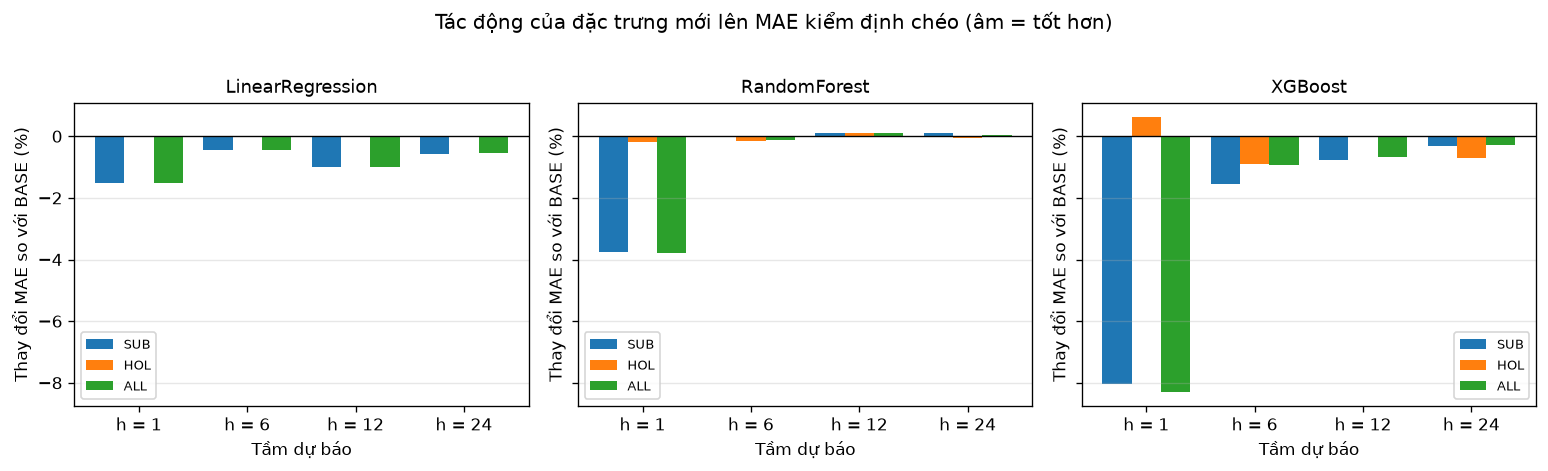

In [13]:
# HINH: cai_tien_dac_trung
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
x = np.arange(len(HORIZONS))
for ax, name in zip(axes, FEAT_MODELS):
    for i, fs in enumerate(["SUB", "HOL", "ALL"]):
        s = feat_delta[(feat_delta.model == name) & (feat_delta.features == fs)].set_index("h").loc[HORIZONS]
        ax.bar(x + (i - 1) * 0.27, s["Thay đổi (%)"], 0.27, label=fs)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x, [f"h = {h}" for h in HORIZONS])
    ax.set(title=name, xlabel="Tầm dự báo", ylabel="Thay đổi MAE so với BASE (%)")
    ax.grid(alpha=0.3, axis="y")
    ax.legend(fontsize=8)
plt.suptitle("Tác động của đặc trưng mới lên MAE kiểm định chéo (âm = tốt hơn)", y=1.02)
plt.tight_layout()
plt.show()

> **Nhận xét cải tiến đặc trưng:**
> - **Công tơ phụ (`SUB`) giúp rõ ở $h = 1$:** XGBoost giảm MAE $8,0\%$ ($0,366 \rightarrow 0,336$ kWh), Random Forest $3,8\%$, Linear Regression $1,5\%$, và tốt hơn ở **cả 5/5 fold** cho cả ba mô hình. Biết thiết bị nào đang chạy giúp đoán giờ kế tiếp, vì một chu trình giặt hay đun nước thường kéo dài quá một giờ.
> - Ở $h \ge 6$ tác động nhỏ ($-1,6\%$ đến $+0,1\%$) ; Linear Regression vẫn cải thiện nhẹ ở 4--5/5 fold, còn với hai mô hình cây kết quả không nhất quán (2--4/5 fold): trạng thái thiết bị cách 6 giờ trở lên không còn liên quan đến giờ mục tiêu.
> - **Ngày lễ (`HOL`) gần như không có tác động** ($-0,9\%$ đến $+0,6\%$, số fold cải thiện 1--4/5, không có xu hướng). Tập huấn luyện chỉ có 768 giờ ngày lễ (32 ngày), quá ít để mô hình học được một mẫu riêng, và hộ này có thể không thay đổi thói quen nhiều vào ngày lễ.
> - Bộ `ALL` cho kết quả gần như trùng `SUB`. Theo quy tắc chọn ở ô dưới, nhóm dùng bộ `SUB` (27 đặc trưng) cho các bước sau. Đây là một cải tiến **không thành công** (ngày lễ) được giữ lại trong báo cáo vì nó vẫn cho biết thông tin về dữ liệu.

In [14]:
# Lựa chọn bộ đặc trưng dùng cho các bước sau (chỉ dựa trên kiểm định chéo):
# bộ có MAE trung bình thấp nhất khi lấy trung bình qua 3 mô hình và 4 tầm dự báo
avg_mae = feat_summary.groupby("features")["mean"].mean().sort_values()
print(avg_mae.round(4))
CHOSEN_FEATURES = avg_mae.index[0]
FEATS = FEATURE_SETS[CHOSEN_FEATURES]
print("Chọn:", CHOSEN_FEATURES, f"({len(FEATS)} đặc trưng)")

features
SUB     0.4598
ALL     0.4600
HOL     0.4652
BASE    0.4658
Name: mean, dtype: float64
Chọn: SUB (27 đặc trưng)


## 6. Tối ưu siêu tham số

- **Phương pháp:** `RandomizedSearchCV` (Random Forest, XGBoost) và `GridSearchCV` (Ridge) của scikit-learn, chấm điểm bằng MAE (`neg_mean_absolute_error`), với `cv` là **chính 5 fold thời gian** của các mục trước (phần kiểm định đã lọc về tập mẫu dùng chung). Tập kiểm tra không tham gia.
- **Vì sao tìm kiếm ngẫu nhiên:** với cùng số lần thử, tìm kiếm ngẫu nhiên khám phá nhiều giá trị khác nhau của mỗi siêu tham số hơn lưới, phù hợp khi chỉ vài siêu tham số thật sự quan trọng.
- **Không gian tìm kiếm** được chọn quanh các giá trị phổ biến và mở rộng theo hướng mà đường cong kiểm định ở mục 4.3 gợi ý.

In [15]:
SPACES = {
    "RandomForest": {"model__min_samples_leaf": [1, 2, 5, 10, 20, 50],
                     "model__max_features": [0.2, 0.33, 0.5, 0.7, 1.0],
                     "model__max_depth": [None, 12, 20]},
    "XGBoost": {"n_estimators": [200, 400, 800],
                "learning_rate": [0.01, 0.03, 0.05, 0.1],
                "max_depth": [3, 4, 5, 6, 8],
                "min_child_weight": [1, 5, 10, 20],
                "subsample": [0.6, 0.8, 1.0],
                "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
                "reg_lambda": [0.1, 1, 10]},
    "Ridge": {"model__alpha": np.logspace(-2, 3, 11)},
}
for k, v in SPACES.items():
    print(k, {p: list(np.round(vals, 3)) if k == "Ridge" else vals for p, vals in v.items()})

RandomForest {'model__min_samples_leaf': [1, 2, 5, 10, 20, 50], 'model__max_features': [0.2, 0.33, 0.5, 0.7, 1.0], 'model__max_depth': [None, 12, 20]}
XGBoost {'n_estimators': [200, 400, 800], 'learning_rate': [0.01, 0.03, 0.05, 0.1], 'max_depth': [3, 4, 5, 6, 8], 'min_child_weight': [1, 5, 10, 20], 'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.5, 0.7, 0.9, 1.0], 'reg_lambda': [0.1, 1, 10]}
Ridge {'model__alpha': [np.float64(0.01), np.float64(0.032), np.float64(0.1), np.float64(0.316), np.float64(1.0), np.float64(3.162), np.float64(10.0), np.float64(31.623), np.float64(100.0), np.float64(316.228), np.float64(1000.0)]}


In [16]:
def search(name, h, cols, n_iter=None, space=None):
    """Tìm siêu tham số cho một mô hình ở một tầm dự báo, trên 5 fold thời gian của tập huấn luyện."""
    train = tables[h][0]
    space = space or SPACES[name]
    est = {"RandomForest": make_random_forest, "XGBoost": make_xgboost, "Ridge": make_ridge}[name](cols)
    kw = dict(cv=cv_folds[h], scoring="neg_mean_absolute_error", refit=False, return_train_score=False)
    if name == "Ridge":
        s = GridSearchCV(est, space, **kw)
    else:
        s = RandomizedSearchCV(est, space, n_iter=n_iter, random_state=RANDOM_STATE, **kw)
    s.fit(train[cols], train["target"])
    res = pd.DataFrame(s.cv_results_)
    return s.best_params_, -s.best_score_, res


t0 = time.time()
best_params, search_log = {}, []
for h in HORIZONS:
    for name, n_iter in (("Ridge", None), ("RandomForest", N_ITER_RF), ("XGBoost", N_ITER_XGB)):
        params, score, res = search(name, h, FEATS, n_iter)
        best_params[(h, name)] = params
        search_log.append(res.assign(h=h, model=name))
        print(f"h = {h:2d} {name:12s} MAE = {score:.4f}  {params}  ({time.time() - t0:.0f} s)", flush=True)
search_log = pd.concat(search_log, ignore_index=True)
search_log[["h", "model", "params", "mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time"]].to_csv(
    RESULTS_DIR / "toi_uu_search_log.csv", index=False)

h =  1 Ridge        MAE = 0.3782  {'model__alpha': np.float64(10.0)}  (3 s)


h =  1 RandomForest MAE = 0.3485  {'model__min_samples_leaf': 5, 'model__max_features': 1.0, 'model__max_depth': None}  (298 s)


h =  1 XGBoost      MAE = 0.3336  {'subsample': 1.0, 'reg_lambda': 10, 'n_estimators': 400, 'min_child_weight': 20, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.9}  (435 s)


h =  6 Ridge        MAE = 0.5062  {'model__alpha': np.float64(0.01)}  (438 s)


h =  6 RandomForest MAE = 0.4808  {'model__min_samples_leaf': 10, 'model__max_features': 0.7, 'model__max_depth': 20}  (769 s)


h =  6 XGBoost      MAE = 0.4741  {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.9}  (930 s)


... (2 outputs left out)

h = 12 XGBoost      MAE = 0.4800  {'subsample': 1.0, 'reg_lambda': 0.1, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.7}  (1414 s)


h = 24 Ridge        MAE = 0.5045  {'model__alpha': np.float64(0.01)}  (1417 s)


h = 24 RandomForest MAE = 0.4932  {'model__min_samples_leaf': 20, 'model__max_features': 0.7, 'model__max_depth': None}  (1707 s)


h = 24 XGBoost      MAE = 0.4918  {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.9}  (1856 s)


In [17]:
def strip_prefix(p):
    """Bỏ tiền tố 'model__' của Pipeline để truyền vào hàm tạo mô hình."""
    return {k.split("__")[-1]: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}

TUNED = {"Ridge": lambda h: (lambda cols: make_ridge(cols, **strip_prefix(best_params[(h, "Ridge")]))),
         "RandomForest": lambda h: (lambda cols: make_random_forest(cols, **strip_prefix(best_params[(h, "RandomForest")]))),
         "XGBoost": lambda h: (lambda cols: make_xgboost(cols, **strip_prefix(best_params[(h, "XGBoost")]))),
         "Voting": lambda h: (lambda cols: make_voting(cols, strip_prefix(best_params[(h, "RandomForest")]),
                                                        strip_prefix(best_params[(h, "XGBoost")])))}
params_table = pd.DataFrame([{"h": h, "Mô hình": m, **strip_prefix(best_params[(h, m)])}
                             for h in HORIZONS for m in ("Ridge", "RandomForest", "XGBoost")])
params_table.to_csv(RESULTS_DIR / "toi_uu_best_params.csv", index=False)
params_table.set_index(["Mô hình", "h"]).sort_index()

alpha  min_samples_leaf  max_features  max_depth  subsample  \
Mô hình      h                                                                 
RandomForest 1     NaN               5.0           1.0        NaN        NaN   
             6     NaN              10.0           0.7       20.0        NaN   
             12    NaN              10.0           0.7       20.0        NaN   
             24    NaN              20.0           0.7        NaN        NaN   
Ridge        1   10.00               NaN           NaN        NaN        NaN   
             6    0.01               NaN           NaN        NaN        NaN   
             12   0.01               NaN           NaN        NaN        NaN   
             24   0.01               NaN           NaN        NaN        NaN   
XGBoost      1     NaN               NaN           NaN        8.0        1.0   
             6     NaN               NaN           NaN        6.0        0.8   
             12    NaN               NaN           NaN        6.0        1.0   
             24    NaN               NaN           NaN        6.0        0.8   

                 reg_lambda  n_estimators  min_child_weight  learning_rate  \
Mô hình      h                                                               
RandomForest 1          NaN           NaN               NaN            NaN   
             6          NaN           NaN               NaN            NaN   
             12         NaN           NaN               NaN            NaN   
             24         NaN           NaN               NaN            NaN   
Ridge        1          NaN           NaN               NaN            NaN   
             6          NaN           NaN               NaN            NaN   
             12         NaN           NaN               NaN            NaN   
             24         NaN           NaN               NaN            NaN   
XGBoost      1         10.0         400.0              20.0           0.03   
             6         10.0         200.0               1.0           0.03   
             12         0.1         800.0              10.0           0.01   
             24        10.0         200.0               1.0           0.03   

                 colsample_bytree  
Mô hình      h                     
RandomForest 1                NaN  
             6                NaN  
             12               NaN  
             24               NaN  
Ridge        1                NaN  
             6                NaN  
             12               NaN  
             24               NaN  
XGBoost      1                0.9  
             6                0.9  
             12               0.7  
             24               0.9

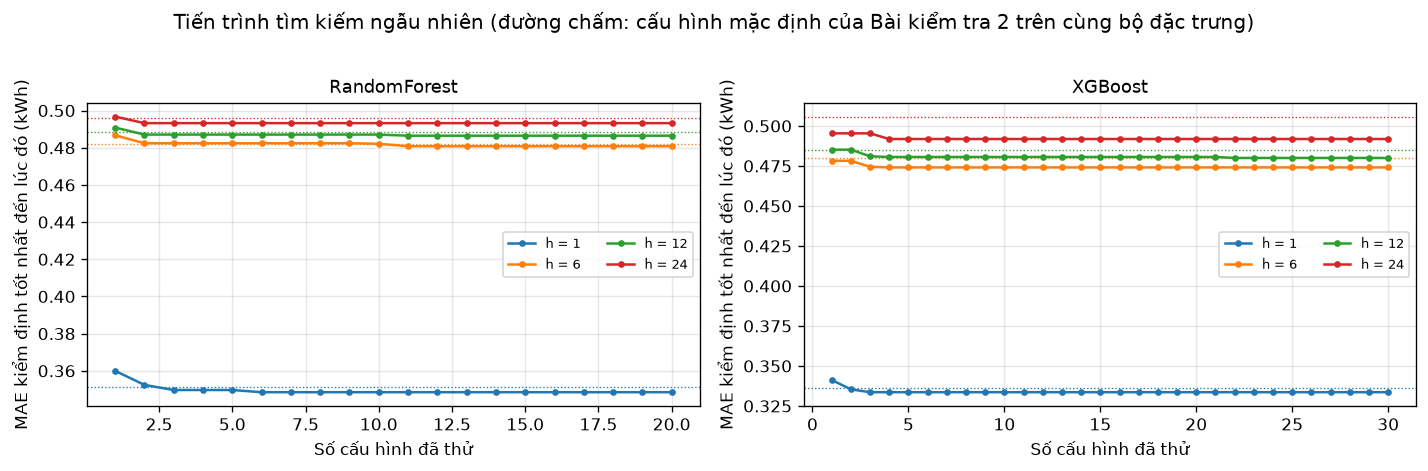

In [18]:
# HINH: tim_kiem
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, name in zip(axes, ("RandomForest", "XGBoost")):
    for h in HORIZONS:
        d = search_log[(search_log.model == name) & (search_log.h == h)]
        best_so_far = (-d["mean_test_score"]).cummin().values
        ax.plot(range(1, len(d) + 1), best_so_far, "o-", ms=3, label=f"h = {h}")
        base_mae = feat_summary[(feat_summary.h == h) & (feat_summary.model == name)
                                & (feat_summary.features == CHOSEN_FEATURES)]["mean"].iloc[0]
        ax.axhline(base_mae, ls=":", lw=0.8, color=ax.lines[-1].get_color())
    ax.set(title=name, xlabel="Số cấu hình đã thử", ylabel="MAE kiểm định tốt nhất đến lúc đó (kWh)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)
plt.suptitle("Tiến trình tìm kiếm ngẫu nhiên (đường chấm: cấu hình mặc định của Bài kiểm tra 2 trên cùng bộ đặc trưng)", y=1.02)
plt.tight_layout()
plt.show()

> **Nhận xét tối ưu siêu tham số:**
> - Mức cải thiện nhỏ so với cấu hình mặc định trên cùng bộ đặc trưng: Random Forest giảm $0,001$--$0,003$ kWh, XGBoost giảm $0,003$ ($h = 1$) đến $0,014$ kWh ($h = 24$, từ $0,506$ xuống $0,492$). Mọi mức cải thiện đều nhỏ hơn độ lệch chuẩn giữa các fold ($0,05$--$0,11$ kWh).
> - Biểu đồ tiến trình cho thấy phần lớn mức cải thiện đạt được trong khoảng 5 lần thử đầu; các cấu hình tìm thấy muộn hơn (lần thử 11 với Random Forest ở $h = 6, 12$; lần thử 22 với XGBoost ở $h = 12$) chỉ tốt hơn thêm dưới $0,002$ kWh. Mở rộng ngân sách tìm kiếm khó cải thiện đáng kể. Điều này khớp với đường cong kiểm định phẳng ở mục 4.3.
> - **Ridge chọn $\alpha$ ở đầu dưới của lưới** ($0,01$ cho $h \ge 6$; $10$ cho $h = 1$ nhưng MAE chỉ khác Linear Regression $0,0003$ kWh): điều chuẩn không giúp vì mô hình tuyến tính chưa khớp chứ không quá khớp.
> - Một số giá trị tối ưu nằm ở biên không gian tìm kiếm (XGBoost độ sâu 8 ở $h = 1$; Random Forest xét 100% đặc trưng ở $h = 1$). Vì chênh lệch giữa các cấu hình tốt rất nhỏ, nhóm không mở rộng thêm không gian.
> - Lưu ý: điểm kiểm định chéo của cấu hình được chọn hơi lạc quan vì chính các fold này được dùng để chọn nó. Ước lượng không bị ảnh hưởng bởi lựa chọn là kết quả trên tập kiểm tra ở mục 9.

## 7. Mô hình mới và so sánh trước -- sau cải tiến (ablation)

Ngoài ba mô hình của Bài kiểm tra 2, nhóm thử:
- **Ridge**: hồi quy tuyến tính có phạt L2, cùng tiền xử lý với Linear Regression; $\alpha$ chọn bằng `GridSearchCV`.
- **Voting**: tổ hợp lấy trung bình dự báo của Random Forest và XGBoost đã tối ưu. Hai mô hình cây có sai số gần nhau nhưng cách xây dựng khác nhau (bagging và boosting), nên lấy trung bình có thể giảm phương sai.

Mọi cấu hình được chạy lại bằng cùng hàm `run_cv` với cùng 5 fold và cùng tập mẫu, nên các dòng trong bảng so sánh được trực tiếp với nhau và với Bài kiểm tra 2.

In [19]:
STEPS = [  # (bước, mô hình, bộ đặc trưng, hàm tạo theo h)
    ("A0. Bài kiểm tra 2", "LinearRegression", "BASE", lambda h: make_linear),
    ("A0. Bài kiểm tra 2", "RandomForest", "BASE", lambda h: make_random_forest),
    ("A0. Bài kiểm tra 2", "XGBoost", "BASE", lambda h: make_xgboost),
    ("A1. + đặc trưng mới", "LinearRegression", CHOSEN_FEATURES, lambda h: make_linear),
    ("A1. + đặc trưng mới", "RandomForest", CHOSEN_FEATURES, lambda h: make_random_forest),
    ("A1. + đặc trưng mới", "XGBoost", CHOSEN_FEATURES, lambda h: make_xgboost),
    ("A2. + tối ưu siêu tham số", "Ridge", CHOSEN_FEATURES, TUNED["Ridge"]),
    ("A2. + tối ưu siêu tham số", "RandomForest", CHOSEN_FEATURES, TUNED["RandomForest"]),
    ("A2. + tối ưu siêu tham số", "XGBoost", CHOSEN_FEATURES, TUNED["XGBoost"]),
    ("A3. + tổ hợp Voting", "Voting", CHOSEN_FEATURES, TUNED["Voting"]),
]
t0 = time.time()
abl_scores, abl_oof = [], []
for h in HORIZONS:
    train = tables[h][0]
    base_done = False
    for step, name, fs, maker in STEPS:
        tic = time.time()
        sc, oof, _ = run_cv(train, FEATURE_SETS[fs], folds[h], models={name: maker(h)})
        fit_time = (time.time() - tic) / N_SPLITS
        if not base_done:                       # mô hình cơ sở chỉ cần lưu một lần cho mỗi h
            abl_scores.append(sc[sc.model.isin(BASELINES)].assign(h=h, step="Mô hình cơ sở", features="-"))
            abl_oof.append(oof[["target", "target_time", "fold"] + BASELINES].assign(h=h))
            base_done = True
        abl_scores.append(sc[sc.model == name].assign(h=h, step=step, features=fs, fit_time=fit_time))
        abl_oof.append(oof[[name]].rename(columns={name: f"{step}|{name}"}).assign(h=h))
    print(f"h = {h:2d}: xong ({time.time() - t0:.0f} s)", flush=True)
abl_scores = pd.concat(abl_scores, ignore_index=True)
abl_scores.to_csv(RESULTS_DIR / "toi_uu_ablation_scores.csv", index=False)

h =  1: xong (110 s)


h =  6: xong (191 s)


h = 12: xong (279 s)


h = 24: xong (354 s)


In [20]:
av = abl_scores[abl_scores.set == "val"]
ablation = (av.groupby(["h", "step", "model", "features"], sort=False)
              .agg(MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"), RMSE_mean=("RMSE", "mean"),
                   MAPE_mean=("MAPE", "mean"), fit_time=("fit_time", "mean")).reset_index())
# Số fold tốt hơn chính mô hình đó ở Bài kiểm tra 2 (A0); Ridge và Voting so với LinearRegression / RandomForest
ref_model = {"Ridge": "LinearRegression", "Voting": "RandomForest"}
a0 = av[av.step.str.startswith("A0")].set_index(["h", "model", "fold"]).MAE
def better_folds(r):
    if r.step.startswith(("A0", "Mô hình")):
        return np.nan
    cur = av[(av.h == r.h) & (av.step == r.step) & (av.model == r.model)].sort_values("fold").MAE.values
    return int((cur < a0.loc[(r.h, ref_model.get(r.model, r.model))].sort_index().values).sum())
# Cột "Số fold tốt hơn A0": so với chính mô hình đó ở A0; Ridge so với LinearRegression A0, Voting so với RandomForest A0
ablation["Số fold tốt hơn A0"] = ablation.apply(better_folds, axis=1)
ablation.to_csv(RESULTS_DIR / "toi_uu_ablation.csv", index=False)
ablation[~ablation.step.eq("Mô hình cơ sở")].pivot_table(
    index=["step", "model"], columns="h", values="MAE_mean", sort=False).round(4)

h                                               1       6       12      24
step                      model                                           
A0. Bài kiểm tra 2        LinearRegression  0.3843  0.5085  0.5094  0.5074
                          RandomForest      0.3651  0.4818  0.4880  0.4953
                          XGBoost           0.3658  0.4875  0.4885  0.5075
A1. + đặc trưng mới       LinearRegression  0.3785  0.5062  0.5043  0.5045
                          RandomForest      0.3513  0.4819  0.4885  0.4958
                          XGBoost           0.3364  0.4799  0.4847  0.5058
A2. + tối ưu siêu tham số RandomForest      0.3485  0.4808  0.4865  0.4932
                          XGBoost           0.3336  0.4741  0.4800  0.4918
                          Ridge             0.3782  0.5062  0.5043  0.5045
A3. + tổ hợp Voting       Voting            0.3371  0.4758  0.4813  0.4908

In [21]:
# Bảng đầy đủ cho h = 1 và h = 24 (trung bình ± độ lệch chuẩn)
def fmt(m, s, d=3):
    return f"{m:.{d}f} ± {s:.{d}f}"
show = ablation[ablation.h.isin([1, 24]) & ~ablation.model.isin(["Mean", "SNaive24"])].copy()
show["MAE"] = [fmt(m, s) for m, s in zip(show.MAE_mean, show.MAE_std)]
show[["h", "step", "model", "features", "MAE", "RMSE_mean", "MAPE_mean", "Số fold tốt hơn A0", "fit_time"]].round(3)

,h,step,model,features,MAE,RMSE_mean,MAPE_mean,Số fold tốt hơn A0,fit_time
1,1,Mô hình cơ sở,Naive,-,0.440 ± 0.069,0.667,46.432,NaN,NaN
3,1,Mô hình cơ sở,SNaive168,-,0.602 ± 0.127,0.883,73.718,NaN,NaN
4,1,A0. Bài kiểm tra 2,LinearRegression,BASE,0.384 ± 0.052,0.545,48.341,NaN,0.084
5,1,A0. Bài kiểm tra 2,RandomForest,BASE,0.365 ± 0.048,0.527,44.361,NaN,2.570
6,1,A0. Bài kiểm tra 2,XGBoost,BASE,0.366 ± 0.056,0.527,44.334,NaN,0.698
7,1,A1. + đặc trưng mới,LinearRegression,SUB,0.378 ± 0.049,0.533,46.661,5.0,0.098
8,1,A1. + đặc trưng mới,RandomForest,SUB,0.351 ± 0.046,0.510,42.200,5.0,2.968
9,1,A1. + đặc trưng mới,XGBoost,SUB,0.336 ± 0.050,0.492,39.057,5.0,0.841
10,1,A2. + tối ưu siêu tham số,Ridge,SUB,0.378 ± 0.050,0.533,46.562,5.0,0.085
11,1,A2. + tối ưu siêu tham số,RandomForest,SUB,0.348 ± 0.046,0.509,41.490,5.0,5.734


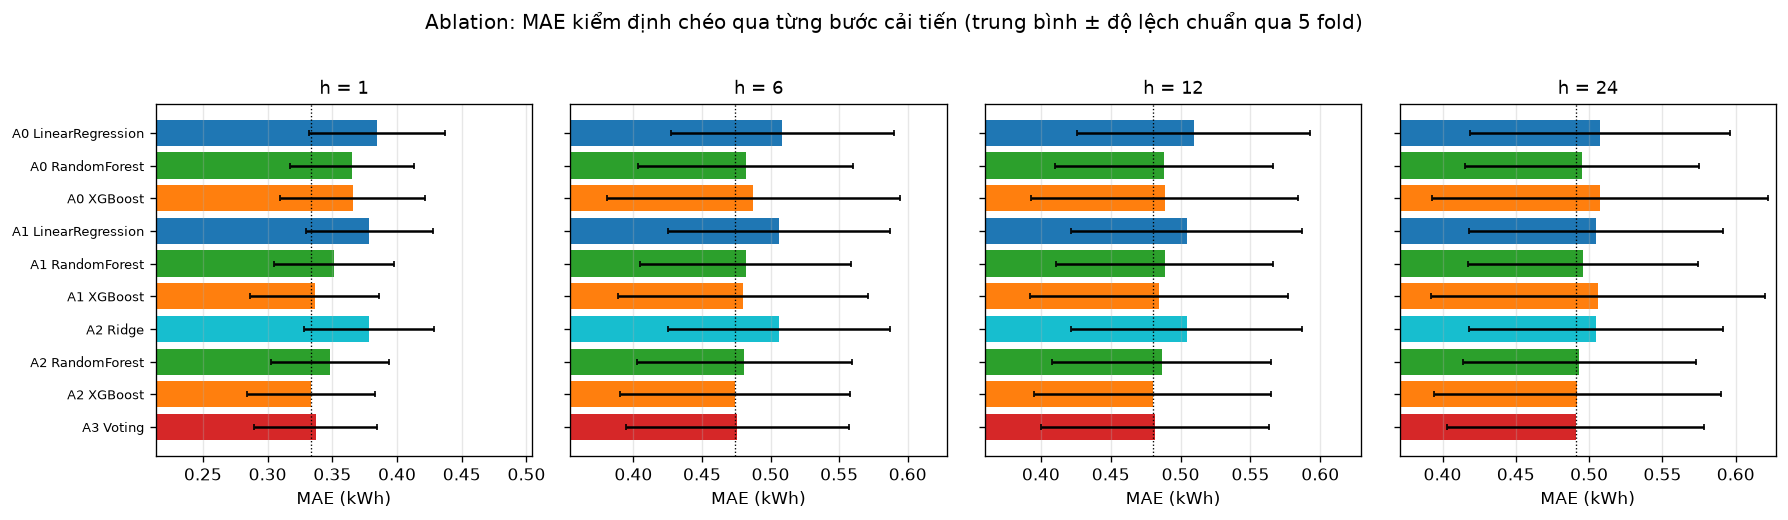

In [22]:
# HINH: ablation
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=False)
for ax, h in zip(axes, HORIZONS):
    d = ablation[(ablation.h == h) & ~ablation.step.eq("Mô hình cơ sở")]
    labels = [f"{s.split('.')[0]} {m}" for s, m in zip(d.step, d.model)]
    ax.barh(range(len(d)), d.MAE_mean, xerr=d.MAE_std, capsize=2,
            color=[colors.get(m, "gray") for m in d.model])
    ax.set_yticks(range(len(d)), labels if h == HORIZONS[0] else [""] * len(d), fontsize=8)
    ax.invert_yaxis()
    lo = d.MAE_mean.min()
    ax.set_xlim(lo - 0.12, d.MAE_mean.max() + 0.12)
    ax.axvline(lo, color="black", ls=":", lw=0.8)
    ax.set(title=f"h = {h}", xlabel="MAE (kWh)")
    ax.grid(alpha=0.3, axis="x")
plt.suptitle("Ablation: MAE kiểm định chéo qua từng bước cải tiến (trung bình ± độ lệch chuẩn qua 5 fold)", y=1.02)
plt.tight_layout()
plt.show()

> **Nhận xét ablation:**
> - **Ở $h = 1$, cải tiến lớn nhất đến từ đặc trưng công tơ phụ:** MAE tốt nhất giảm từ $0,365$ (Random Forest, A0) xuống $0,334$ kWh (XGBoost, A2), tức $8,6\%$; trong đó bước A1 (đặc trưng) đóng góp $0,029$ kWh cho XGBoost, bước A2 (tối ưu) thêm $0,003$ kWh.
> - **Ở $h \ge 6$ cải tiến nhỏ:** MAE tốt nhất giảm $1,6\%$ ($h = 6$, $12$, nhờ XGBoost đã tối ưu) và $0,9\%$ ($h = 24$, Voting; XGBoost đã tối ưu giảm $0,7\%$). Các mức này nhỏ hơn độ lệch chuẩn giữa các fold, nhưng XGBoost A2 tốt hơn XGBoost A0 ở 3--5/5 fold.
> - **Ridge trùng Linear Regression cùng bộ đặc trưng** (A1) đến 4 chữ số thập phân ở $h \ge 6$: xác nhận mô hình tuyến tính bị giới hạn bởi độ chệch.
> - **Voting không tốt hơn mô hình đơn tốt nhất một cách có ý nghĩa:** ở $h = 1$ kém XGBoost ($0,337$ so với $0,334$) vì Random Forest yếu hơn rõ rệt và kéo trung bình lên; ở $h = 24$ tốt hơn XGBoost chỉ $0,001$ kWh ($0,2\%$). Một giải thích có thể là hai mô hình cây học cùng các quan hệ nên sai số giống nhau ở nhiều giờ, khiến lấy trung bình không giảm được bao nhiêu (chưa đo trực tiếp).

## 8. Lựa chọn mô hình cuối

Quy tắc được định trước, chỉ dùng kết quả kiểm định chéo:
1. Ứng viên: các mô hình ở bước A2 và A3 (đã cải tiến đặc trưng và tối ưu).
2. Chọn mô hình có MAE trung bình thấp nhất ở mỗi tầm dự báo.
3. Nếu Voting chỉ tốt hơn mô hình đơn tốt nhất dưới 1% MAE thì chọn mô hình đơn đó: tổ hợp tốn gấp đôi thời gian huấn luyện và khó diễn giải hơn mà lợi ích không đáng kể so với độ lệch giữa các fold.

Lưu ý: điểm kiểm định chéo của các mô hình A2, A3 hơi lạc quan vì siêu tham số được chọn trên chính các fold này. Quy tắc trên chỉ dùng để so sánh các ứng viên với nhau; ước lượng sai số không bị ảnh hưởng bởi lựa chọn là kết quả trên tập kiểm tra ở mục 9.

In [23]:
final_choice = {}
for h in HORIZONS:
    c = ablation[(ablation.h == h) & ablation.step.str.startswith(("A2", "A3"))].set_index("model")
    best_single = c.drop(index="Voting").MAE_mean.idxmin()
    if c.loc["Voting", "MAE_mean"] < c.loc[best_single, "MAE_mean"] * 0.99:
        final_choice[h] = "Voting"
    else:
        final_choice[h] = best_single
choice_table = pd.DataFrame([{
    "h": h, "Mô hình cuối": m,
    "MAE kiểm định chéo": ablation[(ablation.h == h) & (ablation.model == m) & ablation.step.str.startswith(("A2", "A3"))].MAE_mean.iloc[0],
    "Độ lệch chuẩn": ablation[(ablation.h == h) & (ablation.model == m) & ablation.step.str.startswith(("A2", "A3"))].MAE_std.iloc[0],
} for h, m in final_choice.items()])
choice_table.round(4)

,h,Mô hình cuối,MAE kiểm định chéo,Độ lệch chuẩn
0,1,XGBoost,0.3336,0.0497
1,6,XGBoost,0.4741,0.0842
2,12,XGBoost,0.4800,0.0850
3,24,XGBoost,0.4918,0.0978


In [24]:
# Chốt cấu hình vào file TRƯỚC khi chạm tập kiểm tra
final_config = {
    "ghi_chu": "Chọn chỉ dựa trên kiểm định chéo 5 fold trong tập huấn luyện; chưa dùng tập kiểm tra 2010.",
    "bo_dac_trung": CHOSEN_FEATURES,
    "dac_trung": FEATS,
    "mo_hinh": {str(h): {"ten": m,
                         "sieu_tham_so": ({"RandomForest": strip_prefix(best_params[(h, "RandomForest")]),
                                           "XGBoost": strip_prefix(best_params[(h, "XGBoost")])} if m == "Voting"
                                          else strip_prefix(best_params[(h, m)]))}
                for h, m in final_choice.items()},
}
(RESULTS_DIR / "cau_hinh_cuoi.json").write_text(json.dumps(final_config, ensure_ascii=False, indent=2, default=str),
                                               encoding="utf-8")
print(json.dumps(final_config["mo_hinh"], ensure_ascii=False, indent=1, default=str))

{
 "1": {
  "ten": "XGBoost",
  "sieu_tham_so": {
   "subsample": 1.0,
   "reg_lambda": 10,
   "n_estimators": 400,
   "min_child_weight": 20,
   "max_depth": 8,
   "learning_rate": 0.03,
   "colsample_bytree": 0.9
  }
 },
 "6": {
  "ten": "XGBoost",
  "sieu_tham_so": {
   "subsample": 0.8,
   "reg_lambda": 10,
   "n_estimators": 200,
   "min_child_weight": 1,
   "max_depth": 6,
   "learning_rate": 0.03,
   "colsample_bytree": 0.9
  }
 },
 "12": {
  "ten": "XGBoost",
  "sieu_tham_so": {
   "subsample": 1.0,
   "reg_lambda": 0.1,
   "n_estimators": 800,
   "min_child_weight": 10,
   "max_depth": 6,
   "learning_rate": 0.01,
   "colsample_bytree": 0.7
  }
 },
 "24": {
  "ten": "XGBoost",
  "sieu_tham_so": {
   "subsample": 0.8,
   "reg_lambda": 10,
   "n_estimators": 200,
   "min_child_weight": 1,
   "max_depth": 6,
   "learning_rate": 0.03,
   "colsample_bytree": 0.9
  }
 }
}


> **Nhận xét lựa chọn mô hình cuối:** XGBoost đã tối ưu được chọn ở cả bốn tầm dự báo. Ngoài MAE thấp nhất, XGBoost huấn luyện nhanh nhất trong các mô hình cây (dưới 2 giây mỗi fold, so với khoảng $3$--$6$ giây của Random Forest và $4$--$7$ giây của Voting; thời gian thay đổi nhẹ giữa các lần chạy) và xử lý trực tiếp giá trị thiếu. Đánh đổi: độ lệch chuẩn qua các fold của XGBoost ở $h \ge 6$ ($0,084$--$0,098$) lớn hơn Random Forest ($0,078$--$0,079$), tức XGBoost kém ổn định hơn một chút giữa các mùa. Về khả năng diễn giải, hai mô hình cây tương đương (đều cần permutation importance); Ridge dễ diễn giải nhất nhưng MAE kiểm định chéo cao hơn XGBoost $0,013$--$0,045$ kWh. Cấu hình đã được ghi vào `ket_qua/cau_hinh_cuoi.json` trước khi chạm tập kiểm tra.

## 9. Đánh giá mô hình cuối trên tập kiểm tra năm 2010

Đây là mục **duy nhất** sử dụng tập kiểm tra, và chỉ chạy sau khi cấu hình cuối đã được ghi ra file ở mục 8. Kết quả ở đây chỉ để báo cáo, không dùng để chọn lại mô hình hay siêu tham số. Mỗi mô hình được huấn luyện lại trên toàn bộ tập huấn luyện (nhãn đến 31/12/2009) với cấu hình đã chốt, rồi dự báo các giờ của năm 2010 (01/01 -- 26/11/2010). Để thấy tác động của toàn bộ quá trình cải tiến, bảng kết quả gồm cả mô hình cơ sở, mô hình của Bài kiểm tra 2 (A0) và các mô hình đã tối ưu (A2, A3).

In [25]:
t0 = time.time()
test_rows, test_preds = [], {}
for h in HORIZONS:
    train, test = tables[h]
    makers = {"A0 RandomForest": (make_random_forest, BASE), "A0 XGBoost": (make_xgboost, BASE),
              "A0 LinearRegression": (make_linear, BASE)}
    for m in ("Ridge", "RandomForest", "XGBoost", "Voting"):
        makers[f"A2/A3 {m}"] = (TUNED[m](h), FEATS)
    res, pred = evaluate_test(train, test, makers)
    res["Mô hình cuối"] = res.model.eq(f"A2/A3 {final_choice[h]}")
    test_rows.append(res.assign(h=h, n=len(pred)))
    test_preds[h] = pred
    print(f"h = {h:2d}: {len(pred):,} giờ kiểm tra ({time.time() - t0:.0f} s)", flush=True)
test_metrics = pd.concat(test_rows, ignore_index=True)
test_metrics.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
pd.concat([p.assign(h=h) for h, p in test_preds.items()]).to_parquet(RESULTS_DIR / "test_predictions.parquet")
test_metrics.pivot_table(index="model", columns="h", values="MAE", sort=False).round(4)

h =  1: 7,227 giờ kiểm tra (23 s)


h =  6: 7,227 giờ kiểm tra (39 s)


h = 12: 7,227 giờ kiểm tra (57 s)


h = 24: 7,227 giờ kiểm tra (72 s)


h,1,6,12,24
model,,,,
Mean,0.6503,0.6502,0.6502,0.6501
Naive,0.4080,0.8542,0.7153,0.5555
SNaive24,0.5555,0.5555,0.5555,0.5555
SNaive168,0.5768,0.5768,0.5768,0.5768
A0 RandomForest,0.3361,0.4383,0.4442,0.4480
A0 XGBoost,0.3340,0.4403,0.4492,0.4453
A0 LinearRegression,0.3607,0.4697,0.4692,0.4645
A2/A3 Ridge,0.3588,0.4685,0.4661,0.4627
A2/A3 RandomForest,0.3221,0.4381,0.4429,0.4457


In [26]:
# So sánh kiểm định chéo và kiểm tra cho mô hình cuối, mô hình cơ sở tốt nhất và mô hình A0 tương ứng
rows = []
for h in HORIZONS:
    m = final_choice[h]
    cv_final = choice_table.set_index("h").loc[h, "MAE kiểm định chéo"]
    tm = test_metrics[test_metrics.h == h].set_index("model")
    cvb = ablation[(ablation.h == h) & ablation.step.eq("Mô hình cơ sở")].set_index("model").MAE_mean
    best_base_cv = cvb.drop("Mean").idxmin()
    best_base_test = tm.loc[BASELINES].drop("Mean").MAE.idxmin()
    rows.append({"h": h, "Mô hình cuối": m,
                 "MAE kiểm định chéo": cv_final, "MAE kiểm tra": tm.loc[f"A2/A3 {m}", "MAE"],
                 "RMSE kiểm tra": tm.loc[f"A2/A3 {m}", "RMSE"], "MAPE kiểm tra": tm.loc[f"A2/A3 {m}", "MAPE"],
                 "Baseline chọn trên CV": best_base_cv, "MAE baseline đó (kiểm tra)": tm.loc[best_base_cv, "MAE"],
                 "Baseline tốt nhất trên kiểm tra": best_base_test, "MAE (kiểm tra)": tm.loc[best_base_test, "MAE"],
                 "Giảm MAE so với baseline chọn trên CV (%)": 100 * (1 - tm.loc[f"A2/A3 {m}", "MAE"] / tm.loc[best_base_cv, "MAE"]),
                 "A0 RandomForest (kiểm tra)": tm.loc["A0 RandomForest", "MAE"]})
cv_vs_test = pd.DataFrame(rows)
cv_vs_test.to_csv(RESULTS_DIR / "test_cv_vs_test.csv", index=False)
cv_target = pd.read_parquet(RESULTS_DIR / "cv_oof_predictions.parquet").query("h == 1").target.mean()
print(f"Điện năng trung bình trên các giờ được đánh giá: kiểm định chéo (5 fold) {cv_target:.3f} kWh, "
      f"tập kiểm tra 2010 {test_preds[1].target.mean():.3f} kWh")
cv_vs_test.round(3).T

Điện năng trung bình trên các giờ được đánh giá: kiểm định chéo (5 fold) 1.120 kWh, tập kiểm tra 2010 1.055 kWh


,0,1,2,3
h,1,6,12,24
Mô hình cuối,XGBoost,XGBoost,XGBoost,XGBoost
MAE kiểm định chéo,0.334,0.474,0.48,0.492
MAE kiểm tra,0.313,0.434,0.439,0.441
RMSE kiểm tra,0.459,0.6,0.604,0.603
MAPE kiểm tra,38.158,58.674,60.16,61.321
Baseline chọn trên CV,Naive,SNaive168,SNaive168,SNaive168
MAE baseline đó (kiểm tra),0.408,0.577,0.577,0.577
Baseline tốt nhất trên kiểm tra,Naive,SNaive24,SNaive24,Naive
MAE (kiểm tra),0.408,0.556,0.556,0.556


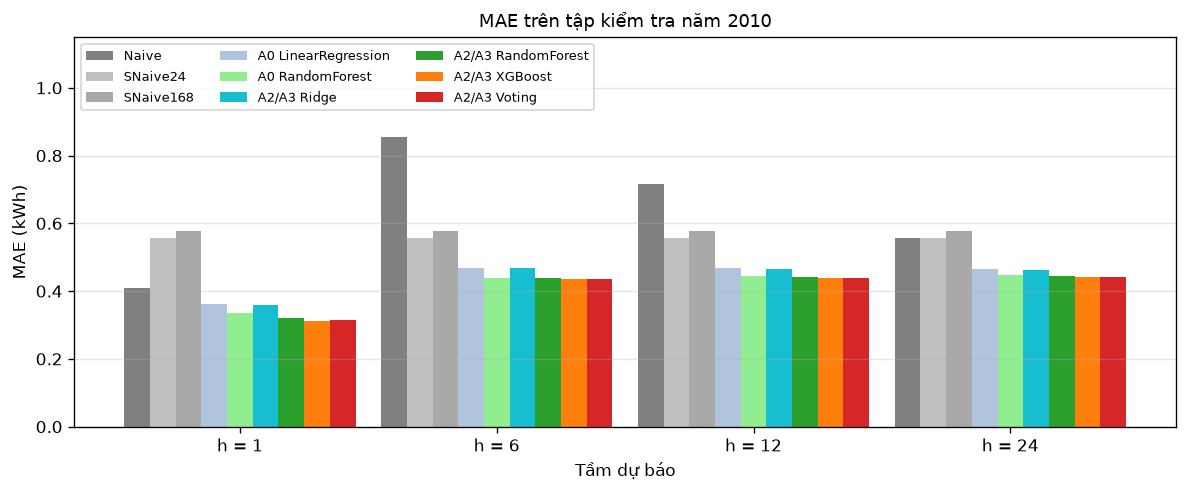

In [27]:
# HINH: test_so_sanh
fig, ax = plt.subplots(figsize=(10, 4.2))
show_models = ["Naive", "SNaive24", "SNaive168", "A0 LinearRegression", "A0 RandomForest",
               "A2/A3 Ridge", "A2/A3 RandomForest", "A2/A3 XGBoost", "A2/A3 Voting"]
cmap = {"Naive": "gray", "SNaive24": "silver", "SNaive168": "darkgray", "A0 LinearRegression": "lightsteelblue",
        "A0 RandomForest": "lightgreen", "A2/A3 Ridge": "tab:cyan", "A2/A3 RandomForest": "tab:green",
        "A2/A3 XGBoost": "tab:orange", "A2/A3 Voting": "tab:red"}
x = np.arange(len(HORIZONS))
w = 0.1
for i, m in enumerate(show_models):
    s = test_metrics[test_metrics.model == m].set_index("h").loc[HORIZONS, "MAE"]
    ax.bar(x + (i - 4) * w, s, w, color=cmap[m], label=m)
ax.set_xticks(x, [f"h = {h}" for h in HORIZONS])
ax.set(xlabel="Tầm dự báo", ylabel="MAE (kWh)", title="MAE trên tập kiểm tra năm 2010")
ax.set_ylim(0, 1.15)
ax.grid(alpha=0.3, axis="y")
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

> **Nhận xét kết quả trên tập kiểm tra:**
> - **Mô hình cuối (XGBoost) vượt mọi mô hình cơ sở ở cả bốn tầm dự báo:** MAE $0,313$ ($h = 1$), $0,434$, $0,439$, $0,441$ kWh ($h = 6, 12, 24$), thấp hơn $23$--$25\%$ so với mô hình cơ sở được chọn trên kiểm định chéo (Naive ở $h = 1$, SNaive168 ở $h \ge 6$). So với mô hình cơ sở tốt nhất **trên chính tập kiểm tra** (SNaive24, $0,556$ kWh ở $h \ge 6$), mức giảm vẫn là $20,6$--$21,8\%$.
> - **Thứ hạng giữ nguyên như kiểm định chéo:** XGBoost đã tối ưu tốt nhất ở mọi $h$, Voting sát sau ($0,314$--$0,442$), Ridge gần như bằng Linear Regression. So với Random Forest của Bài kiểm tra 2, mô hình cuối giảm MAE $6,9\%$ ở $h = 1$ ($0,336 \rightarrow 0,313$) và $0,9$--$1,6\%$ ở $h \ge 6$, khớp với kết luận của bảng ablation.
> - **MAE trên tập kiểm tra thấp hơn MAE kiểm định chéo** ($0,313$ so với $0,334$ ở $h = 1$; $0,441$ so với $0,492$ ở $h = 24$). Đây không phải dấu hiệu rò rỉ vì mô hình cơ sở cũng thấp hơn tương tự (Naive $0,408$ so với $0,440$; SNaive168 $0,577$ so với $0,602$): năm 2010 có mức tiêu thụ trung bình thấp hơn ($1,055$ so với $1,120$ kWh ở phần kiểm định của 5 fold) nên dễ dự báo hơn, và mô hình cuối được huấn luyện trên nhiều dữ liệu hơn mọi fold.
> - Thứ hạng giữa hai mô hình cơ sở mùa vụ đảo ngược (SNaive168 tốt hơn trên kiểm định chéo, SNaive24 tốt hơn trên kiểm tra), cho thấy chênh lệch nhỏ giữa chúng không ổn định qua các giai đoạn.

In [28]:
# Độ ổn định theo hạt giống ngẫu nhiên: huấn luyện lại mô hình cuối (cấu hình đã chốt, không đổi) với
# 5 hạt giống khác nhau. Chỉ để đo biến động do tính ngẫu nhiên của thuật toán, không dùng để chọn hạt giống.
def with_seed(make, seed):
    def f(cols):
        m = make(cols)
        for k in m.get_params():
            if k.endswith("random_state"):
                m.set_params(**{k: seed})
        return m
    return f

t0 = time.time()
seed_rows = []
for h in HORIZONS:
    train, test = tables[h]
    makers = {f"seed {s}": (with_seed(TUNED[final_choice[h]](h), s), FEATS) for s in SEEDS}
    res, _ = evaluate_test(train, test, makers)
    seed_rows.append(res[res.model.str.startswith("seed")].assign(h=h))
seeds = pd.concat(seed_rows, ignore_index=True)
seeds.to_csv(RESULTS_DIR / "test_seeds.csv", index=False)
print(f"Thời gian: {time.time() - t0:.0f} giây")
seeds.groupby("h").MAE.agg(["mean", "std", "min", "max"]).round(4)

Thời gian: 20 giây


,mean,std,min,max
h,,,,
1,0.3112,0.0004,0.3108,0.3117
6,0.4346,0.0005,0.4341,0.4352
12,0.4399,0.0008,0.4392,0.4409
24,0.4417,0.0007,0.4408,0.4426


> **Nhận xét độ ổn định theo hạt giống:** huấn luyện lại mô hình cuối với 5 hạt giống ngẫu nhiên khác nhau cho MAE kiểm tra dao động rất nhỏ (độ lệch chuẩn $0,0004$--$0,0008$ kWh, chênh lệch lớn nhất $0,0018$ kWh). Biến động do tính ngẫu nhiên của thuật toán nhỏ hơn nhiều so với chênh lệch giữa các mô hình và so với biến động giữa các fold ($0,05$--$0,11$ kWh, chủ yếu do mùa). Kết quả của mô hình cuối vì vậy không phụ thuộc vào một lần chạy may mắn.

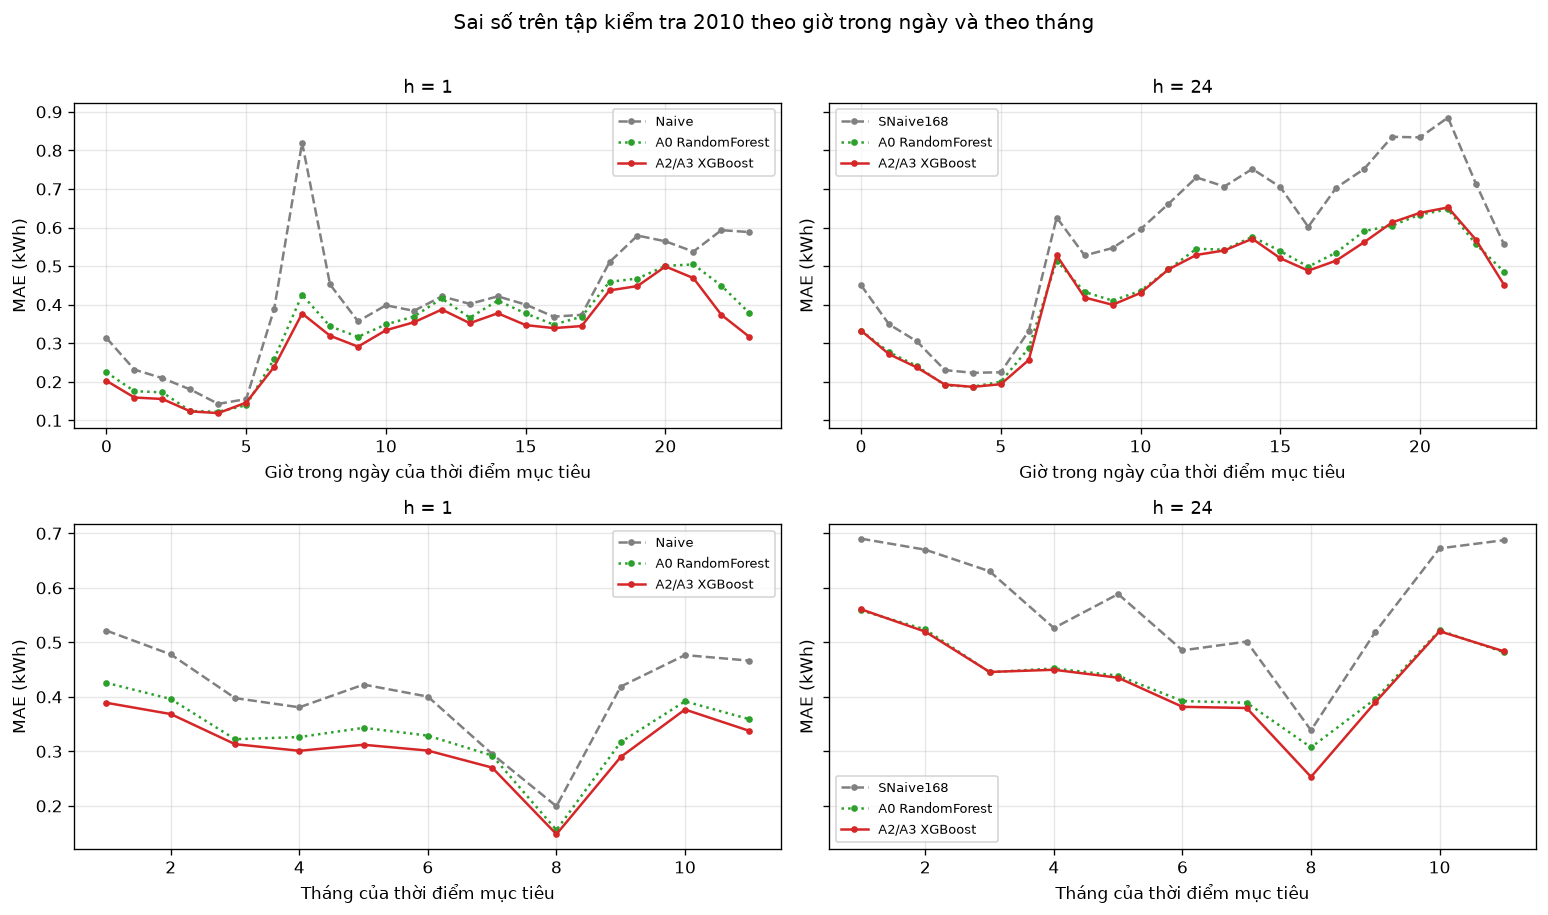

In [29]:
# HINH: test_theo_gio_thang
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharey="row")
for c, h in enumerate((1, 24)):
    p = test_preds[h]
    fm = f"A2/A3 {final_choice[h]}"
    bb = cv_vs_test.set_index("h").loc[h, "Baseline chọn trên CV"]
    for r, (key, xl) in enumerate(((p.target_time.dt.hour, "Giờ trong ngày của thời điểm mục tiêu"),
                                    (p.target_time.dt.month, "Tháng của thời điểm mục tiêu"))):
        ax = axes[r, c]
        for m, st, col in ((bb, "--", "gray"), ("A0 RandomForest", ":", "tab:green"), (fm, "-", "tab:red")):
            e = (p[m] - p.target).abs().groupby(key).mean()
            ax.plot(e.index, e.values, st, marker=".", color=col, label=m)
        ax.set(title=f"h = {h}", xlabel=xl, ylabel="MAE (kWh)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.suptitle("Sai số trên tập kiểm tra 2010 theo giờ trong ngày và theo tháng", y=1.01)
plt.tight_layout()
plt.show()

In [30]:
# Lỗi tập trung trên tập kiểm tra (mô hình cuối) và trường hợp tháng 8 ở h = 24
rows = []
for h in HORIZONS:
    p = test_preds[h]
    err = p[f"A2/A3 {final_choice[h]}"] - p.target
    q95 = p.target.quantile(0.95)
    top10 = err.abs() >= err.abs().quantile(0.90)
    aug = p.target_time.dt.month == 8
    rows.append({"h": h, "Ngưỡng 5% giờ cao nhất (kWh)": q95,
                 "Sai lệch TB ở 5% giờ cao nhất (kWh)": err[p.target >= q95].mean(),
                 "Tỷ trọng sai số của 10% giờ sai nhiều nhất (%)": 100 * err.abs()[top10].sum() / err.abs().sum(),
                 "Tháng 8: MAE mô hình cuối": err[aug].abs().mean(),
                 "Tháng 8: MAE SNaive24": (p.SNaive24 - p.target)[aug].abs().mean(),
                 "Tháng 8: sai lệch TB mô hình cuối": err[aug].mean(),
                 "Tháng 8: điện năng TB": p.target[aug].mean()})
test_errors = pd.DataFrame(rows)
test_errors.to_csv(RESULTS_DIR / "test_error_concentration.csv", index=False)
test_errors.round(3).T

,0,1,2,3
h,1.000,6.000,12.000,24.000
Ngưỡng 5% giờ cao nhất (kWh),2.567,2.567,2.567,2.567
Sai lệch TB ở 5% giờ cao nhất (kWh),-0.898,-1.317,-1.299,-1.322
Tỷ trọng sai số của 10% giờ sai nhiều nhất (%),34.955,31.425,31.384,30.843
Tháng 8: MAE mô hình cuối,0.148,0.229,0.232,0.253
Tháng 8: MAE SNaive24,0.188,0.188,0.188,0.188
Tháng 8: sai lệch TB mô hình cuối,0.005,0.039,0.049,0.060
Tháng 8: điện năng TB,0.506,0.506,0.506,0.506


> **Nhận xét sai số trên tập kiểm tra theo giờ và tháng:**
> - Mẫu sai số giống kiểm định chéo: thấp nhất lúc 3--4 giờ sáng ($0,12$ kWh ở $h = 1$), cao nhất buổi tối 19--21 giờ ($0,45$--$0,50$ kWh ở $h = 1$; $0,61$--$0,65$ kWh ở $h = 24$).
> - Ở $h = 1$, mô hình cuối giảm mạnh nhất ở 7 giờ sáng so với Naive ($0,820 \rightarrow 0,377$ kWh). Ở $h = 24$, giảm mạnh nhất ở buổi tối so với SNaive168 (21 giờ: $0,885 \rightarrow 0,652$ kWh).
> - Theo tháng, sai số cao nhất tháng 1 ($0,389$ kWh ở $h = 1$; $0,561$ ở $h = 24$) và thấp nhất tháng 8 ($0,148$; $0,253$). **Tháng 8 là trường hợp mô hình cuối kém một mô hình cơ sở ở mọi $h \ge 6$:** SNaive24 chỉ $0,188$ kWh, còn XGBoost $0,229$--$0,253$ kWh (ở $h = 24$ dự báo cao trung bình $0,06$ kWh); ở $h = 1$ XGBoost vẫn tốt hơn Naive ($0,148$ so với $0,199$). Tháng 8 tiêu thụ thấp và đều ($0,51$ kWh trung bình trên các giờ được đánh giá), nên lặp lại ngày hôm trước đã rất tốt; mô hình học từ cả năm nên kéo dự báo về mức tiêu thụ chung cao hơn.
> - Mô hình cuối vẫn dự báo thấp các đỉnh: ở 5% giờ cao nhất (từ $2,57$ kWh), dự báo thấp trung bình $0,90$ kWh ($h = 1$) và $1,32$ kWh ($h = 24$); 10% giờ sai nhiều nhất chiếm $35,0\%$ và $30,8\%$ tổng sai số. So với kiểm định chéo của Bài kiểm tra 2 ($1,06$--$1,15$ và $1,44$--$1,63$ kWh), mức dự báo thấp ở đỉnh đã giảm nhưng chưa hết.

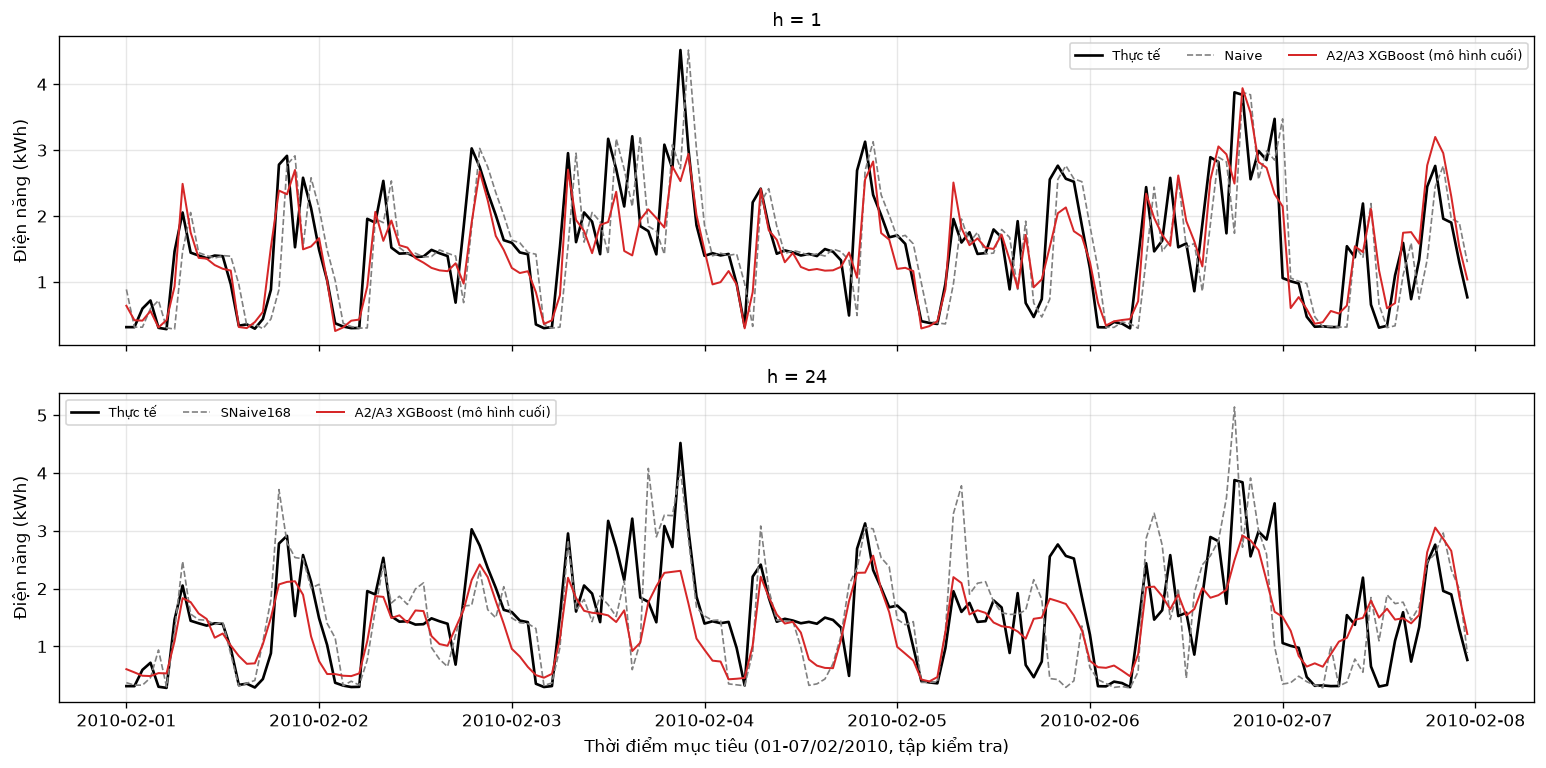

h =  1: đỉnh thực tế 4.52 kWh lúc 2010-02-03 21:00:00, mô hình cuối dự báo 2.53 kWh
h = 24: đỉnh thực tế 4.52 kWh lúc 2010-02-03 21:00:00, mô hình cuối dự báo 2.31 kWh


In [31]:
# HINH: test_tuan_vi_du
week = slice("2010-02-01", "2010-02-07")
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for ax, h in zip(axes, (1, 24)):
    p = test_preds[h].set_index("target_time").loc[week]
    fm = f"A2/A3 {final_choice[h]}"
    bb = cv_vs_test.set_index("h").loc[h, "Baseline chọn trên CV"]
    ax.plot(p.index, p.target, color="black", lw=1.6, label="Thực tế")
    ax.plot(p.index, p[bb], "--", color="gray", lw=1, label=bb)
    ax.plot(p.index, p[fm], color="tab:red", lw=1.2, label=f"{fm} (mô hình cuối)")
    ax.set(title=f"h = {h}", ylabel="Điện năng (kWh)")
    ax.grid(alpha=0.3)
    ax.legend(ncol=3, fontsize=8)
axes[1].set_xlabel("Thời điểm mục tiêu (01-07/02/2010, tập kiểm tra)")
plt.tight_layout()
plt.show()
for h in (1, 24):
    p = test_preds[h].set_index("target_time").loc[week]
    t_max = p.target.idxmax()
    print(f"h = {h:2d}: đỉnh thực tế {p.target.max():.2f} kWh lúc {t_max}, "
          f"mô hình cuối dự báo {p.loc[t_max, f'A2/A3 {final_choice[h]}']:.2f} kWh")

> **Nhận xét tuần ví dụ (01--07/02/2010):**
> - Với $h = 1$, mô hình cuối theo sát đường thực tế; nhiều lần tăng đột ngột được bắt kịp sớm hơn Naive (đường Naive luôn trễ đúng một giờ). Đỉnh lớn nhất tuần ($4,52$ kWh lúc 21 giờ ngày 03/02) vẫn bị dự báo thấp ($2,53$ kWh).
> - Với $h = 24$, mô hình cuối cho đường trơn, tái hiện nhịp tăng buổi sáng và buổi tối hằng ngày nhưng không đoán được các đỉnh riêng lẻ (đỉnh ngày 03/02 chỉ dự báo $2,31$ kWh). SNaive168 sao chép tuần trước nên có nhiều đỉnh không xảy ra trong tuần này.

## 10. Hàm thao tác nhanh khi vấn đáp

- `thu_tim_kiem(ten, h, khong_gian, n_iter)`: chạy lại tìm kiếm siêu tham số với một không gian tìm kiếm tùy chọn, trên cùng 5 fold.
- `ve_duong_cong_kiem_dinh(ten, h, tham_so, gia_tri)`: vẽ đường cong kiểm định cho một siêu tham số bất kỳ.

Cả hai hàm chỉ dùng tập huấn luyện.

In [32]:
def thu_tim_kiem(ten="XGBoost", h=1, khong_gian=None, n_iter=10):
    params, score, res = search(ten, h, FEATS, n_iter, khong_gian)
    print(f"{ten}, h = {h}: MAE tốt nhất = {score:.4f} kWh với {strip_prefix(params)}")
    cols = ["params", "mean_test_score", "std_test_score"]
    return res.sort_values("rank_test_score")[cols].head(5).assign(
        mean_test_score=lambda d: -d.mean_test_score).round(4)


def ve_duong_cong_kiem_dinh(ten="RandomForest", h=1, tham_so="min_samples_leaf", gia_tri=(1, 5, 20, 50)):
    make = {"RandomForest": make_random_forest, "XGBoost": make_xgboost, "Ridge": make_ridge}[ten]
    out = []
    for v in gia_tri:
        sc, _, _ = run_cv(tables[h][0], FEATS, folds[h], models={ten: lambda cols, v=v: make(cols, **{tham_so: v})})
        sc = sc[sc.model == ten]
        out.append({"giá trị": v, "MAE huấn luyện": sc[sc.set == "train"].MAE.mean(),
                    "MAE kiểm định": sc[sc.set == "val"].MAE.mean(), "độ lệch chuẩn": sc[sc.set == "val"].MAE.std()})
    out = pd.DataFrame(out)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(out["giá trị"], out["MAE huấn luyện"], "o-", label="Huấn luyện (trong mẫu)")
    ax.errorbar(out["giá trị"], out["MAE kiểm định"], yerr=out["độ lệch chuẩn"], fmt="s-", capsize=3, label="Kiểm định")
    ax.set(xlabel=tham_so, ylabel="MAE (kWh)", title=f"{ten}, h = {h}")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()
    return out.round(4)


thu_tim_kiem("XGBoost", 1, {"max_depth": [3, 5, 7], "learning_rate": [0.03, 0.1]}, n_iter=4)

XGBoost, h = 1: MAE tốt nhất = 0.3339 kWh với {'max_depth': 7, 'learning_rate': 0.03}


,params,mean_test_score,std_test_score
3,"{'max_depth': 7, 'learning_rate': 0.03}",0.3339,0.0429
1,"{'max_depth': 5, 'learning_rate': 0.03}",0.3350,0.0431
2,"{'max_depth': 7, 'learning_rate': 0.1}",0.3498,0.0478
0,"{'max_depth': 3, 'learning_rate': 0.03}",0.3509,0.0448


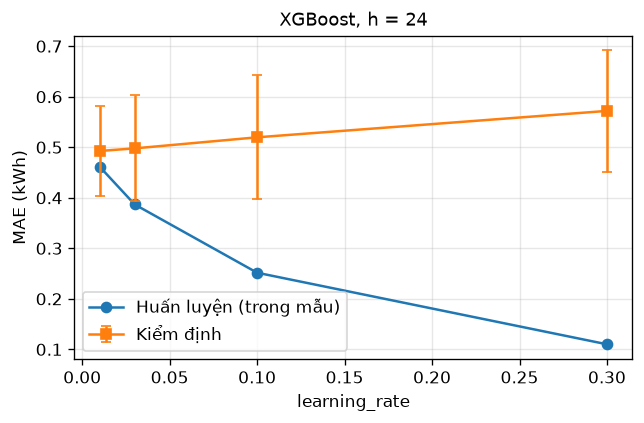

,giá trị,MAE huấn luyện,MAE kiểm định,độ lệch chuẩn
0,0.01,0.4615,0.4926,0.0892
1,0.03,0.3868,0.4978,0.1049
2,0.10,0.2517,0.5197,0.1230
3,0.30,0.1101,0.5719,0.1199


In [33]:
ve_duong_cong_kiem_dinh("XGBoost", 24, "learning_rate", (0.01, 0.03, 0.1, 0.3))

> **Ví dụ thao tác:**
> - Tìm kiếm nhỏ cho XGBoost ở $h = 1$ (4 cấu hình) chọn độ sâu 7, tốc độ học $0,03$ với MAE $0,334$ kWh, xấp xỉ kết quả của tìm kiếm đầy đủ ($0,334$).
> - Đường cong kiểm định theo tốc độ học của XGBoost ở $h = 24$ (400 cây, độ sâu 6): khi tốc độ học tăng từ $0,01$ lên $0,3$, MAE huấn luyện giảm từ $0,46$ xuống $0,11$ kWh nhưng MAE kiểm định tăng từ $0,493$ lên $0,572$ kWh. Đây là ví dụ rõ về quá khớp: mỗi cây hiệu chỉnh quá mạnh nên mô hình học cả nhiễu. Tốc độ học $0,05$ của Bài kiểm tra 2 và $0,03$ của cấu hình cuối nằm ở vùng an toàn.

## 11. Tổng kết

**Kết quả chính của Bài kiểm tra 3:**
1. Đường cong kiểm định cho thấy khoảng cách giữa sai số trong mẫu và sai số kiểm định của mô hình cây **không phải quá khớp gây hại**: giảm độ phức tạp không làm sai số kiểm định giảm. Linear Regression chưa khớp, điều chuẩn Ridge không giúp.
2. Cải tiến hiệu quả nhất là **đặc trưng công tơ phụ** tại $t$ và $t-1$: giảm MAE của XGBoost $8\%$ ở $h = 1$, tốt hơn ở 5/5 fold. Đặc trưng ngày lễ không có tác động rõ.
3. Tối ưu siêu tham số bằng tìm kiếm ngẫu nhiên trên 5 fold chỉ cải thiện thêm $0,1$--$3\%$; tổ hợp Voting không tốt hơn mô hình đơn tốt nhất một cách có ý nghĩa.
4. Mô hình cuối là **XGBoost đã tối ưu với 27 đặc trưng** ở cả bốn tầm dự báo. Trên tập kiểm tra 2010 (dùng một lần), MAE là $0,313$ / $0,434$ / $0,439$ / $0,441$ kWh với $h = 1 / 6 / 12 / 24$, thấp hơn $23$--$25\%$ so với mô hình cơ sở chọn trên kiểm định chéo; kết quả ổn định theo hạt giống (độ lệch chuẩn $< 0,001$ kWh).
5. Hạn chế còn lại: dự báo thấp các giờ đỉnh, kém SNaive24 vào tháng 8 ở $h \ge 6$, và cải tiến ở $h \ge 6$ chỉ khoảng $1$--$2\%$, cho thấy giới hạn của thông tin có trong dữ liệu điện năng của một hộ.